# Oral Diseases — PyTorch training on Kaggle T4 x2

**Sprint 2 / Project 01.** This is a self-contained initial five-model experiment: custom CNN, EfficientNet-B0, MobileNetV3-Large, ResNet50, and ResNet101. Two settings per model provide a small tuning comparison. Validation macro-F1 selects the settings and overall winner; test data is used only after all selections are recorded. The five-model plan extends the assignment's custom CNN + 2–3 pretrained models.

## Before Run All

1. Attach **salmansajid05/oral-diseases, version 3** using Add Input.
2. Select **GPU T4 x2** and turn **Internet ON** for pinned Python packages and the official ImageNet checkpoints. Alternatively attach the exact four `.pth` files named in the weight preflight below; then internet is unnecessary.
3. Choose **Save Version → Save & Run All** for the unattended run. No other notebook, local script, or local audit CSV is required.

The notebook rebuilds the inventory and fixed experimental split, checks all five models with a real DDP backward/optimizer step, then trains. It includes early stopping, per-epoch checkpoints, resume support when outputs are preserved, and final reports. Maximum training allocation is **9 hours per invocation**; a budget-limited run saves a resumable status rather than claiming completion. Actual total runtime and model quality are not guaranteed.

## Data policy

A local audit read and hash-verified all 3,898 distinct source images, visually inspected 120 samples across six classes, and confirmed rotated/mirrored variants crossing the former proposed split. This notebook uses the corrected **eight-orientation pHash grouping**, quarantines multi-label families, and keeps every detected family in one split. The measured default inventory is 3,448 eligible images in 1,812 families, targeting 2,415 / 518 / 515 train / validation / test images. It checks the computed result rather than copying a prebuilt split.

Small images, watermarks, collages, exposure edits, and uncertain folder labels remain. Geometry flags are retained as metadata; labels are not clinically revalidated. Patient independence cannot be established. This is an initial coursework experiment, not evidence of clinical readiness. No healthy class exists; license metadata is Unknown.

Sources: [dataset](https://www.kaggle.com/datasets/salmansajid05/oral-diseases), [PyTorch DDP](https://docs.pytorch.org/docs/stable/generated/torch.nn.parallel.DistributedDataParallel.html), [AMP](https://docs.pytorch.org/docs/stable/amp.html), [TorchVision weights](https://docs.pytorch.org/vision/stable/models.html).

**Library versions:** the startup cell pins the directly used third-party data packages and Ultralytics to the effective local Conda `main` versions. Kaggle retains its previously observed PyTorch 2.11.0+cu128 / TorchVision 0.26.0+cu128 GPU pair because the local TorchVision 0.20.1+cu121 does not provide a Python 3.13 wheel. IPython is reported as the already-running kernel rather than replaced in place. Versions are recorded in the experiment runtime report. If packages needing an update were already imported, the cell installs them and requests a kernel restart before proceeding.

In [1]:
import sys, subprocess, tempfile, platform, random, hashlib, io, json
from pathlib import Path
from zipfile import ZipFile
from collections import Counter
from importlib.metadata import version, PackageNotFoundError

# Versions used by this notebook and its embedded training script.
LOCAL_PACKAGE_PINS = {
    'ultralytics': '8.4.191',
    'numpy': '2.4.6',
    'pandas': '3.0.3',
    'matplotlib': '3.11.0',
    'Pillow': '12.3.0',
    'scikit-learn': '1.9.1',
    'scipy': '1.17.1',
}

LOCAL_RUNTIME_VERSIONS = {
    'torch': '2.5.1+cu121',
    'torchvision': '0.20.1+cu121',
    'ipython': '9.16.1',
}

KAGGLE_GPU_STACK = {
    'torch': '2.11.0+cu128',
    'torchvision': '0.26.0+cu128',
}

MODULE_NAMES = {
    'ultralytics': 'ultralytics',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'Pillow': 'PIL',
    'scikit-learn': 'sklearn',
    'scipy': 'scipy',
}


def installed_version(package):
    try:
        return version(package)
    except PackageNotFoundError:
        return None


ON_KAGGLE = Path('/kaggle/input').is_dir()
gpu_stack = {
    name: installed_version(name)
    for name in ('torch', 'torchvision')
}

if any(v is None for v in gpu_stack.values()):
    raise RuntimeError(
        'PyTorch or TorchVision is missing from the notebook environment.'
    )

if ON_KAGGLE and gpu_stack != KAGGLE_GPU_STACK:
    raise RuntimeError(
        f'Kaggle GPU stack {gpu_stack} differs from the tested '
        f'stack {KAGGLE_GPU_STACK}. Check it before training.'
    )

# A previous pip install can leave old versions in the running kernel.
stale = []
for package, module_name in MODULE_NAMES.items():
    module = sys.modules.get(module_name)
    loaded = getattr(module, '__version__', None) if module is not None else None

    if loaded is not None and str(loaded) != LOCAL_PACKAGE_PINS[package]:
        stale.append(
            f'{package}: loaded {loaded}, need {LOCAL_PACKAGE_PINS[package]}'
        )

if stale:
    raise RuntimeError(
        'Old packages are still loaded. Restart the notebook kernel, '
        'then run this cell again: ' + '; '.join(stale)
    )

mismatched = {
    name: (installed_version(name), wanted)
    for name, wanted in LOCAL_PACKAGE_PINS.items()
    if installed_version(name) != wanted
}

if mismatched:
    already_loaded = [
        name for name in mismatched
        if MODULE_NAMES[name] in sys.modules
    ]

    print('Installing missing or mismatched versions:', mismatched, flush=True)

    with tempfile.TemporaryDirectory(prefix='oral_package_constraints_') as temporary:
        constraints = Path(temporary) / 'constraints.txt'
        constraints.write_text(
            ''.join(f'{name}=={value}\n' for name, value in gpu_stack.items())
        )

        command = [
            sys.executable, '-m', 'pip', 'install', '--no-cache-dir',
            '--upgrade', '--constraint', str(constraints)
        ]
        command += [
            f'{name}=={wanted}'
            for name, wanted in LOCAL_PACKAGE_PINS.items()
        ]
        subprocess.check_call(command)

    if already_loaded:
        raise RuntimeError(
            'Packages installed, but old versions are loaded: '
            + ', '.join(already_loaded)
            + '. Restart the notebook kernel, then run this cell again.'
        )
else:
    print('Pinned libraries are already installed; no installation needed.')

import ultralytics
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
import sklearn
import scipy
import torch
import torchvision
import IPython
from PIL import Image, ImageOps
from IPython.display import display

modules = {
    'ultralytics': ultralytics,
    'numpy': np,
    'pandas': pd,
    'matplotlib': matplotlib,
    'Pillow': PIL,
    'scikit-learn': sklearn,
    'scipy': scipy,
}

for package, module in modules.items():
    if str(module.__version__) != LOCAL_PACKAGE_PINS[package]:
        raise RuntimeError(
            f'{package} loaded as {module.__version__}; '
            'restart the kernel and run again.'
        )

library_versions = {
    name: str(module.__version__)
    for name, module in modules.items()
}
library_versions.update({
    'torch': str(torch.__version__),
    'torchvision': str(torchvision.__version__),
    'ipython': str(IPython.__version__),
})

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print('Effective package versions:', library_versions)
print('Python:', platform.python_version(), '| CUDA:', torch.version.cuda)

Pinned libraries are already installed; no installation needed.
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Effective package versions: {'ultralytics': '8.4.191', 'numpy': '2.4.6', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'Pillow': '12.3.0', 'scikit-learn': '1.9.1', 'scipy': '1.17.1', 'torch': '2.11.0+cu128', 'torchvision': '0.26.0+cu128', 'ipython': '7.34.0'}
Python: 3.13.15 | CUDA: 12.8


## 0. Verify PyTorch and both T4 GPUs

Selecting T4 x2 allocates two independent GPUs. Each has its own memory; they do not become one pooled GPU. A plain `model.to('cuda')` uses only one GPU.

The cell below checks names, available memory, TorchVision compatibility, and a small FP16 matrix computation on **each** visible GPU. On Kaggle it stops with a useful message if two T4s are not visible. Local CPU/single-GPU checks remain possible, but cannot establish Kaggle readiness. Seeds improve repeatability; they do not guarantee bit-for-bit agreement between different machines or distributed runs.

In [2]:
ON_KAGGLE = Path('/kaggle/input').is_dir()
print('PyTorch:', torch.__version__, '| TorchVision:', torchvision.__version__)
print('PyTorch CUDA build:', torch.version.cuda)
gpu_count = torch.cuda.device_count() if torch.cuda.is_available() else 0
print('Visible CUDA GPUs:', gpu_count)
gpu_info = []
for index in range(gpu_count):
    properties = torch.cuda.get_device_properties(index)
    free_bytes, total_bytes = torch.cuda.mem_get_info(index)
    info = {'index': index, 'name': properties.name,
            'total_memory_GiB': round(total_bytes / 2**30, 2),
            'free_memory_GiB': round(free_bytes / 2**30, 2),
            'compute_capability': f'{properties.major}.{properties.minor}'}
    gpu_info.append(info)
    print(info)
if ON_KAGGLE and (gpu_count != 2 or not all('T4' in info['name'] for info in gpu_info)):
    raise RuntimeError('This notebook targets Kaggle T4 x2. Select GPU T4 x2 under Accelerator and restart the session, then run again.')

for info in gpu_info:
    device = torch.device(f"cuda:{info['index']}")
    with torch.no_grad():
        x = torch.randn(64, 64, device=device, dtype=torch.float16)
        y = x @ x.T
        assert torch.isfinite(y).all().item(), f'Non-finite smoke-test result on {device}'
        torch.cuda.synchronize(device)
        print(f"GPU {info['index']} FP16 computation passed: {info['name']}")
        del x, y
print('Readiness:', 'Kaggle T4 x2 checks passed' if ON_KAGGLE else 'Local check only; dual-T4 validation still requires Kaggle')

# Proposed training defaults. No model is trained in this inspection notebook.
TRAINING_PLAN = {
    'framework': 'pytorch', 'target': 'kaggle_t4_x2',
    'strategy': 'DistributedDataParallel', 'processes': 2,
    'image_size': 224, 'precision': 'fp16_autocast_with_grad_scaler',
    'batch_size_per_gpu': 32, 'global_batch_size': 64,
    'resnet101_initial_batch_size_per_gpu': 16,
    'resnet101_initial_global_batch_size': 32,
    'dataloader_workers_per_process': 2, 'pin_memory': True,
    'persistent_workers': True, 'non_blocking_device_transfer': True,
    'checkpoint_selection_metric': 'validation_macro_f1',
    'seed': SEED,
    'status': 'Starting settings to benchmark in the future training notebook; not tuned hyperparameters or measured throughput.'
}
runtime_report = {'python': platform.python_version(), 'torch': str(torch.__version__),
                  'torchvision': str(torchvision.__version__), 'cuda_build': torch.version.cuda,
                  'gpu_count': gpu_count, 'gpus': gpu_info,
                  'dual_t4_verified_here': bool(ON_KAGGLE), 'training_plan': TRAINING_PLAN}
display(pd.Series(TRAINING_PLAN, name='planned_training_setting').to_frame())


PyTorch: 2.11.0+cu128 | TorchVision: 0.26.0+cu128
PyTorch CUDA build: 12.8
Visible CUDA GPUs: 2
{'index': 0, 'name': 'Tesla T4', 'total_memory_GiB': 14.56, 'free_memory_GiB': 14.46, 'compute_capability': '7.5'}
{'index': 1, 'name': 'Tesla T4', 'total_memory_GiB': 14.56, 'free_memory_GiB': 14.46, 'compute_capability': '7.5'}
GPU 0 FP16 computation passed: Tesla T4
GPU 1 FP16 computation passed: Tesla T4
Readiness: Kaggle T4 x2 checks passed


,planned_training_setting
framework,pytorch
target,kaggle_t4_x2
strategy,DistributedDataParallel
processes,2
image_size,224
precision,fp16_autocast_with_grad_scaler
batch_size_per_gpu,32
global_batch_size,64
resnet101_initial_batch_size_per_gpu,16
resnet101_initial_global_batch_size,32


## 1. Find the correct source folders

The archive mixes classification photographs, pre-augmented copies, and a separate YOLO detection dataset. Use the six explicit source folders below. Do not use every top-level folder as a class. Some directory names contain spelling mistakes and even a trailing space; preserve them when reading paths.

In [3]:
PREFIXES = {
    'Calculus': 'Calculus/Calculus/',
    'Caries': 'Data caries/Data caries/caries orignal data set/done/',
    'Gingivitis': 'Gingivitis/Gingivitis/',
    'Hypodontia': 'hypodontia/hypodontia/',
    'Mouth Ulcer': 'Mouth Ulcer/Mouth Ulcer/ulcer original dataset/ulcer original dataset/',
    'Tooth Discoloration': 'Tooth Discoloration/Tooth Discoloration /tooth discoloration original dataset/tooth discoloration original dataset/',
}
CLASSES = list(PREFIXES)
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff', '.gif'}
EXPECTED_ZIP_SHA256 = '0f17eb5efff8ceba5ecb00b2667cebaa6d014c0e1ae44d160ecc30a9de64a367'
ON_KAGGLE = Path('/kaggle/input').is_dir()
archive = None
source_zip = None
root = None

if ON_KAGGLE:
    possible_roots = {d.parent for d in Path('/kaggle/input').rglob('Calculus') if d.is_dir()}
    roots = sorted(r for r in possible_roots if all((r / prefix).is_dir() for prefix in PREFIXES.values()))
    if len(roots) != 1:
        raise RuntimeError(f'Expected one attached Oral Diseases v3 dataset; found {roots}. Check Add Input and version.')
    root = roots[0]
    paths = sorted(f.relative_to(root).as_posix() for f in root.rglob('*') if f.is_file())
    def read_bytes(path):
        return (root / path).read_bytes()
    output_dir = Path('/kaggle/working/oral_inspection')
    print('Mounted dataset:', root)
else:
    projects = [Path.cwd(), Path.cwd().parent]
    project = next((r for r in projects if (r / 'data/raw/oral-diseases-v3.zip').is_file()), None)
    if project is None:
        raise FileNotFoundError('Run locally from the project folder or its notebooks folder, or attach the dataset on Kaggle.')
    archive = project / 'data/raw/oral-diseases-v3.zip'
    digest = hashlib.sha256()
    with archive.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    assert digest.hexdigest() == EXPECTED_ZIP_SHA256, 'The local archive differs from the audited v3 source.'
    source_zip = ZipFile(archive)
    paths = sorted(info.filename for info in source_zip.infolist() if not info.is_dir())
    def read_bytes(path):
        return source_zip.read(path)
    output_dir = project / 'research/kaggle_starter_check'
    print('Verified local v3 ZIP:', archive.name)

output_dir.mkdir(parents=True, exist_ok=True)
print('Top-level folders:', sorted({name.split('/')[0] for name in paths}))
selected = []
for name in paths:
    if Path(name).suffix.lower() not in EXTENSIONS:
        continue
    label = next((label for label, prefix in PREFIXES.items() if name.startswith(prefix)), None)
    if label is not None:
        selected.append({'path': name, 'class': label})
assert {r['class'] for r in selected} == set(CLASSES), 'One or more source classes are missing.'
raw_counts = pd.Series(Counter(r['class'] for r in selected)).reindex(CLASSES).rename('source_files')
display(raw_counts.to_frame())
if len(selected) != 5563:
    raise RuntimeError(f'Found {len(selected)} classification files, expected 5563 for audited v3. Check the dataset version before continuing.')

Mounted dataset: /kaggle/input/datasets/salmansajid05/oral-diseases
Top-level folders: ['Calculus', 'Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset', 'Data caries', 'Gingivitis', 'Mouth Ulcer', 'Tooth Discoloration', 'hypodontia']


,source_files
Calculus,1296
Caries,219
Gingivitis,2349
Hypodontia,1251
Mouth Ulcer,265
Tooth Discoloration,183


## 2. Look before modeling

These are examples of the supplied folder labels. Inspect resolution, framing, watermarks, lighting, and whether multiple conditions might appear in one image. Plot originals without stretching them into squares.

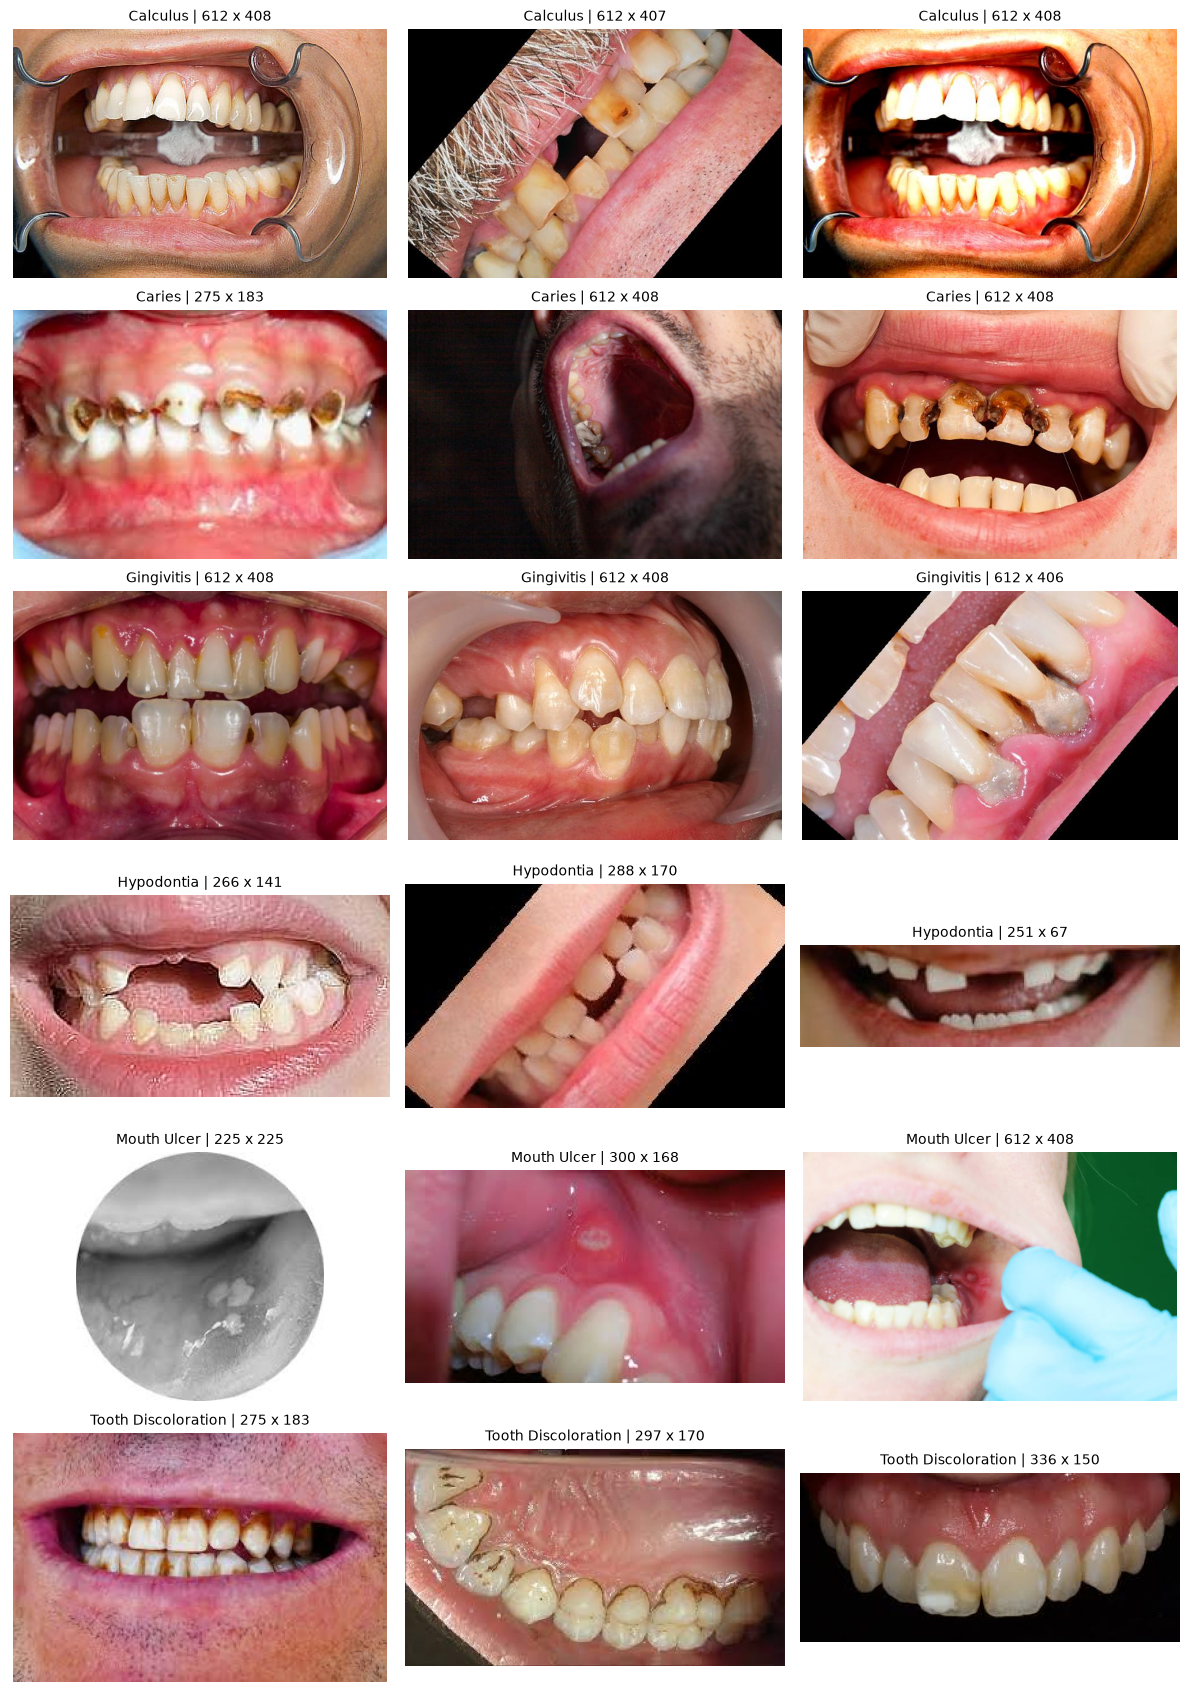

In [4]:
def load_rgb(path):
    with Image.open(io.BytesIO(read_bytes(path))) as im:
        return ImageOps.exif_transpose(im).convert('RGB')

fig, axes = plt.subplots(len(CLASSES), 3, figsize=(12, 17))
for row, label in enumerate(CLASSES):
    examples = [r for r in selected if r['class'] == label]
    for ax, sample in zip(axes[row], random.Random(SEED).sample(examples, 3)):
        im = load_rgb(sample['path'])
        ax.imshow(im)
        ax.set_title(f'{label} | {im.width} x {im.height}', fontsize=10)
        ax.axis('off')
plt.tight_layout()
fig.savefig(output_dir / 'source_samples.png', dpi=120)
plt.show()
plt.close(fig)

## 3. Decode and identify exact copies

Hash the dimensions and decoded RGB pixels after applying image orientation. This catches identical decoded pictures even when file bytes differ. Keep decode failures in the audit. This step may take a few minutes on CPU.

In [5]:
records = []
for i, item in enumerate(selected, start=1):
    record = dict(item, width=None, height=None, pixel_sha256='', decode_error='')
    try:
        im = load_rgb(item['path'])
        record.update(width=im.width, height=im.height,
                      pixel_sha256=hashlib.sha256(str(im.size).encode() + b':' + im.tobytes()).hexdigest())
    except Exception as exc:
        record['decode_error'] = f'{type(exc).__name__}: {exc}'
    records.append(record)
    if i % 1000 == 0:
        print(f'Inspected {i}/{len(selected)}')
manifest = pd.DataFrame(records)
valid = manifest.loc[manifest['decode_error'].eq('')].copy()
failures = manifest.loc[manifest['decode_error'].ne('')].copy()
print('Readable:', len(valid), '| Decode failures:', len(failures))
if not failures.empty:
    display(failures)
valid['short_edge'] = valid[['width', 'height']].min(axis=1)
display(valid.groupby('class').agg(files=('path', 'size'),
    min_short_edge=('short_edge', 'min'), median_short_edge=('short_edge', 'median')))

Inspected 1000/5563
Inspected 2000/5563
Inspected 3000/5563
Inspected 4000/5563
Inspected 5000/5563
Readable: 5563 | Decode failures: 0


,files,min_short_edge,median_short_edge
class,,,
Calculus,1296,125,408.0
Caries,219,77,258.0
Gingivitis,2349,130,408.0
Hypodontia,1251,33,156.0
Mouth Ulcer,265,120,188.0
Tooth Discoloration,183,104,183.0


## 4. Set label conflicts aside and retain one exact representative

An identical image under two labels is ambiguous for this single-label exercise. Quarantine all such groups; do not guess a new diagnosis. Remaining exact duplicates contribute one representative each. This produces a **provisional inventory**, not a fully cleaned dataset: crops, recompressions, similar scenes, and questionable labels still need review.

,source_files,provisional_candidates
Calculus,1296,448
Caries,219,191
Gingivitis,2349,1236
Hypodontia,1251,1215
Mouth Ulcer,265,243
Tooth Discoloration,183,173


Distinct decoded source images: 3898
Conflicting exact-image groups: 392
Provisional candidates: 3506


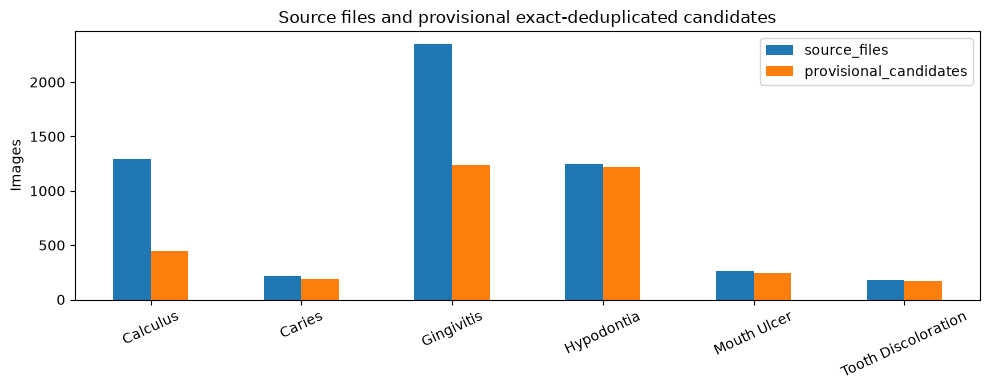

In [6]:
labels_per_hash = valid.groupby('pixel_sha256')['class'].nunique()
conflicting_hashes = set(labels_per_hash.index[labels_per_hash > 1])
conflicts = valid.loc[valid['pixel_sha256'].isin(conflicting_hashes)].copy()
candidates = (valid.loc[~valid['pixel_sha256'].isin(conflicting_hashes)]
              .sort_values('path').drop_duplicates('pixel_sha256').reset_index(drop=True))
counts = pd.concat([raw_counts, candidates['class'].value_counts().reindex(CLASSES).rename('provisional_candidates')], axis=1)
display(counts)
print('Distinct decoded source images:', valid['pixel_sha256'].nunique())
print('Conflicting exact-image groups:', len(conflicting_hashes))
print('Provisional candidates:', len(candidates))
expected = {'Calculus': 448, 'Caries': 191, 'Gingivitis': 1236,
            'Hypodontia': 1215, 'Mouth Ulcer': 243, 'Tooth Discoloration': 173}
assert candidates['class'].value_counts().to_dict() == expected, 'Counts differ from the audited v3 source; investigate before splitting.'
assert len(conflicting_hashes) == 392
ax = counts.plot.bar(figsize=(10, 4), rot=25, title='Source files and provisional exact-deduplicated candidates')
ax.set_ylabel('Images')
plt.tight_layout()
plt.savefig(output_dir / 'class_counts.png', dpi=120)
plt.show()
plt.close()

## 5. Inspect one conflict and save the evidence

The images in a conflict group have identical decoded pixels. The displayed titles show the conflicting folder labels. This is a data issue that a random train/test split would hide.

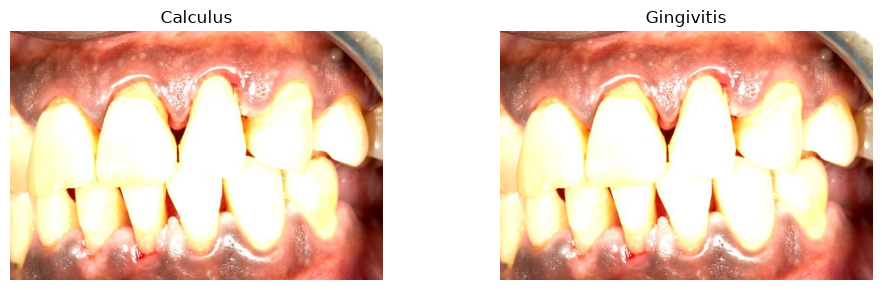

Saved inspection outputs: /kaggle/working/oral_inspection
Exact audit complete. Continue to orientation-aware family preparation below.


In [7]:
example_hash = sorted(conflicting_hashes)[0]
example = conflicts.loc[conflicts['pixel_sha256'].eq(example_hash)].drop_duplicates('class')
fig, axes = plt.subplots(1, len(example), figsize=(5 * len(example), 3), squeeze=False)
for ax, (_, row) in zip(axes[0], example.iterrows()):
    ax.imshow(load_rgb(row['path']))
    ax.set_title(row['class'])
    ax.axis('off')
plt.tight_layout()
plt.show()
plt.close(fig)

manifest.to_csv(output_dir / 'source_manifest.csv', index=False)
conflicts.to_csv(output_dir / 'exact_label_conflicts.csv', index=False)
candidates.to_csv(output_dir / 'provisional_candidates.csv', index=False)
counts.to_csv(output_dir / 'class_counts.csv')
(output_dir / 'class_to_idx.json').write_text(json.dumps({label: i for i, label in enumerate(CLASSES)}, indent=2))
summary = {
    'dataset': 'salmansajid05/oral-diseases', 'expected_version': 3, 'seed': SEED,
    'source_files': len(manifest), 'decode_failures': len(failures),
    'unique_decoded_images': int(valid['pixel_sha256'].nunique()),
    'cross_label_groups': len(conflicting_hashes), 'provisional_candidates': len(candidates),
    'status': 'Near-duplicate, source-family, quality and questionable-label review still required; no frozen split.',
    'source_zip_sha256': EXPECTED_ZIP_SHA256 if archive is not None else None,
    'version_verification': 'ZIP SHA-256 verified locally' if archive is not None else 'Mounted counts checked; ZIP hash not available',
    'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
}
(output_dir / 'inspection_summary.json').write_text(json.dumps(summary, indent=2))
(output_dir / 'pytorch_runtime.json').write_text(json.dumps(runtime_report, indent=2))
(output_dir / 'training_plan.json').write_text(json.dumps(TRAINING_PLAN, indent=2))
if source_zip is not None:
    source_zip.close()
print('Saved inspection outputs:', output_dir)
print('Exact audit complete. Continue to orientation-aware family preparation below.')

## 6. Restore the inspection results and source reader

The previous inspection cell closes the local ZIP. Reopen it here when working locally. On Kaggle, read the attached dataset directly. Outputs for this stage go to `/kaggle/working/oral_preparation`.

No additional packages or internet connection are needed.

In [8]:
from pathlib import Path
from zipfile import ZipFile
from collections import Counter
import hashlib, io, json, math, os, random, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
import torch
import torchvision
from torchvision import transforms
from torch import nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
CLASSES = ['Calculus', 'Caries', 'Gingivitis', 'Hypodontia', 'Mouth Ulcer', 'Tooth Discoloration']
CLASS_TO_IDX = {label: index for index, label in enumerate(CLASSES)}
ON_KAGGLE = Path('/kaggle/input').is_dir()
if ON_KAGGLE:
    output_dir = Path('/kaggle/working/oral_inspection')
    source_roots = sorted({d.parent for d in Path('/kaggle/input').rglob('Calculus')
                           if d.is_dir() and (d.parent / 'Calculus/Calculus').is_dir()
                           and (d.parent / 'hypodontia/hypodontia').is_dir()})
    if len(source_roots) != 1:
        raise RuntimeError('Attach exactly one Oral Diseases v3 dataset and rerun the inspection.')
    data_root = source_roots[0]
    zip_path = None
else:
    project = next((d for d in [Path.cwd(), Path.cwd().parent]
                    if (d / 'data/raw/oral-diseases-v3.zip').is_file()), None)
    if project is None:
        raise FileNotFoundError('Run locally from this project or its notebooks folder.')
    output_dir = project / 'research/kaggle_starter_check'
    data_root = None
    zip_path = project / 'data/raw/oral-diseases-v3.zip'
    if 'preparation_zip' in globals():
        preparation_zip.close()
    preparation_zip = ZipFile(zip_path)

prep_dir = output_dir.parent / 'oral_preparation'
prep_dir.mkdir(parents=True, exist_ok=True)
required_files = ['source_manifest.csv', 'provisional_candidates.csv']
for name in required_files:
    if not (output_dir / name).is_file():
        raise FileNotFoundError(f'Missing {name}. Run the original inspection cells first.')
source_manifest = pd.read_csv(output_dir / 'source_manifest.csv', keep_default_na=False)
provisional = pd.read_csv(output_dir / 'provisional_candidates.csv', keep_default_na=False)
assert len(source_manifest) == 5563 and len(provisional) == 3506
assert source_manifest['decode_error'].eq('').all()
source_manifest[['width', 'height']] = source_manifest[['width', 'height']].astype(int)
provisional[['width', 'height']] = provisional[['width', 'height']].astype(int)
representatives = source_manifest.sort_values('path').drop_duplicates('pixel_sha256').reset_index(drop=True)
assert len(representatives) == 3898

def read_preparation_rgb(relative_path):
    content = ((data_root / relative_path).read_bytes() if data_root is not None
               else preparation_zip.read(relative_path))
    with Image.open(io.BytesIO(content)) as im:
        return ImageOps.exif_transpose(im).convert('RGB')

source_fingerprint = hashlib.sha256(
    source_manifest.sort_values('path')[['path','class','pixel_sha256']]
    .to_csv(index=False).encode('utf-8')).hexdigest()
print('Restored:', len(source_manifest), 'source records and', len(provisional), 'candidates')
print('Preparation outputs:', prep_dir)

Restored: 5563 source records and 3506 candidates
Preparation outputs: /kaggle/working/oral_preparation


## 7. Find related pictures across rotations and mirror flips

The deeper local inspection found mirrored and rotated pictures crossing the earlier proposed split. The previous orientation-only check is superseded by this eight-orientation scan: identity, rotations by 90/180/270 degrees, and their mirror images. A 64-bit DCT perceptual hash flags distance 0–4 between all 3,898 distinct original pictures, including quarantined exact-conflict pictures so that family links are preserved.

These are conservative grouping candidates, not clinical labels. The first run reads images on CPU; later runs use a source-keyed hash cache. This still does not guarantee detection of crops, arbitrary angles, collages, or other same-patient views.

In [9]:
PHASH_DISTANCE = 4
PHASH_ALGORITHM = 'dct32_low8_rgb_dihedral_v2'
VARIANTS = ['identity','rotate90','rotate180','rotate270','mirror','mirror_rotate90','mirror_rotate180','mirror_rotate270']
N = 32
DCT = np.cos(np.pi * (2 * np.arange(N)[None, :] + 1) * np.arange(8)[:, None] / (2 * N))
def hash_gray(gray):
    coefficients = (DCT @ gray @ DCT.T).ravel()
    bits = coefficients > np.median(coefficients[1:])
    bits[0] = False
    result = 0
    for bit in bits:
        result = (result << 1) | int(bit)
    return f'{result:016x}'

cache_path = prep_dir / f'phashes_{PHASH_ALGORITHM}_{source_fingerprint[:16]}.csv'
if cache_path.is_file():
    cached = pd.read_csv(cache_path, dtype=str, keep_default_na=False)
    assert cached['pixel_sha256'].is_unique
    assert set(cached['pixel_sha256']) == set(representatives['pixel_sha256'])
    for variant in VARIANTS:
        assert cached[variant].str.fullmatch(r'[0-9a-f]{16}').all()
    hashes = cached.set_index('pixel_sha256').loc[representatives['pixel_sha256'], VARIANTS]
    print('Loaded cached hashes for all eight orientations.')
else:
    records = []
    for index, row in enumerate(representatives.itertuples(index=False), 1):
        gray = np.asarray(read_preparation_rgb(row.path).convert('L').resize((N,N), Image.Resampling.LANCZOS), dtype=np.float32)
        record = {'pixel_sha256':row.pixel_sha256}
        for rotation in range(4):
            record[VARIANTS[rotation]] = hash_gray(np.rot90(gray,rotation))
            record[VARIANTS[rotation+4]] = hash_gray(np.rot90(np.fliplr(gray),rotation))
        records.append(record)
        if index % 1000 == 0: print(f'Hashed {index}/{len(representatives)} source images')
    cached = pd.DataFrame(records)
    cached.to_csv(cache_path,index=False)
    hashes = cached.set_index('pixel_sha256').loc[representatives['pixel_sha256'], VARIANTS]

original_hashes = np.array([int(value,16) for value in hashes['identity']], dtype=np.uint64)
lookup_bits = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
edge_records = {}
for variant in VARIANTS:
    variant_hashes = np.array([int(value,16) for value in hashes[variant]], dtype=np.uint64)
    for start in range(0,len(representatives),256):
        differences = variant_hashes[start:start+256,None] ^ original_hashes[None,:]
        if hasattr(np,'bitwise_count'):
            distances = np.bitwise_count(differences)
        else:
            distances = lookup_bits[differences.view(np.uint8).reshape(*differences.shape,8)].sum(axis=-1)
        lefts,rights = np.where(distances <= PHASH_DISTANCE)
        for offset,right in zip(lefts,rights):
            left,right = start+int(offset),int(right)
            if left >= right: continue
            distance = int(distances[offset,right])
            key = (left,right)
            if key not in edge_records or distance < edge_records[key][0]:
                edge_records[key] = (distance,variant)
pairs = pd.DataFrame([(left,right,distance,variant) for (left,right),(distance,variant) in sorted(edge_records.items())],
                     columns=['left_index','right_index','distance','transform'])
for side in ['left','right']:
    pairs[f'{side}_path'] = pairs[f'{side}_index'].map(representatives['path'])
    pairs[f'{side}_hash'] = pairs[f'{side}_index'].map(representatives['pixel_sha256'])
    pairs[f'{side}_class'] = pairs[f'{side}_index'].map(representatives['class'])
pairs.to_csv(prep_dir/'near_similarity_pairs.csv',index=False)
print('Flagged similarity pairs over eight orientations:',len(pairs))
display(pairs.groupby('transform').size().rename('pairs').to_frame())


Hashed 1000/3898 source images
Hashed 2000/3898 source images
Hashed 3000/3898 source images
Flagged similarity pairs over eight orientations: 4978


,pairs
transform,
identity,1961
mirror,1331
mirror_rotate180,1312
rotate180,374


## 8. Build conservative image-family groups

Treat flagged pairs as links in a graph. Connected pictures stay together, including chains A–B–C even when A and C have distance greater than 4. Grouping can over-merge unrelated pictures; the review sheets help us assess this.

For this single-label baseline, set aside every family that contains more than one original folder label, including original exact-label conflicts. This quarantines ambiguous families without choosing a diagnosis. Similar pictures with one consistent label remain available in the **same split**; they are not automatically deleted.

`MANUAL_FAMILY_LINKS` can add visually confirmed links the hash missed. `EXCLUDE_PATHS` records reviewed exclusions with a reason. Leave them empty for this first proposal and inspect the outputs before freezing it.

In [10]:
# Edit only after inspecting images. Use exact relative paths from the CSVs.
MANUAL_FAMILY_LINKS = []  # [(relative_path_a, relative_path_b), ...]
EXCLUDE_PATHS = {}       # {relative_path: 'documented visual exclusion reason', ...}

parent = list(range(len(representatives)))
def find_family(index):
    while parent[index] != index:
        parent[index] = parent[parent[index]]
        index = parent[index]
    return index
def connect(left, right):
    left, right = find_family(left), find_family(right)
    if left != right:
        parent[max(left, right)] = min(left, right)
for pair in pairs.itertuples(index=False):
    connect(pair.left_index, pair.right_index)
index_by_hash = {value: index for index, value in enumerate(representatives['pixel_sha256'])}
hash_by_path = source_manifest.set_index('path')['pixel_sha256'].to_dict()
for left_path, right_path in MANUAL_FAMILY_LINKS:
    if left_path not in hash_by_path or right_path not in hash_by_path:
        raise ValueError('A manual family link uses an unknown source path.')
    connect(index_by_hash[hash_by_path[left_path]], index_by_hash[hash_by_path[right_path]])
unknown_exclusions = set(EXCLUDE_PATHS) - set(hash_by_path)
if unknown_exclusions or any(not str(reason).strip() for reason in EXCLUDE_PATHS.values()):
    raise ValueError(f'Exclusions need valid paths and nonempty reasons: {unknown_exclusions}')

members = {}
for index, digest in enumerate(representatives['pixel_sha256']):
    members.setdefault(find_family(index), []).append(digest)
# Stable group IDs depend on the full member hashes, not filenames or input row order.
family_ids = {root: 'family_' + hashlib.sha256('|'.join(sorted(hashes)).encode()).hexdigest()[:20]
              for root, hashes in members.items()}
family_by_hash = {digest: family_ids[find_family(index)]
                  for index, digest in enumerate(representatives['pixel_sha256'])}
family_sources = source_manifest.copy()
family_sources['family_id'] = family_sources['pixel_sha256'].map(family_by_hash)
family_stats = family_sources.groupby('family_id').agg(
    folder_labels=('class', lambda values: ' | '.join(sorted(set(values)))),
    label_count=('class', 'nunique'), distinct_images=('pixel_sha256', 'nunique'), source_files=('path', 'size'))
conflicting_families = set(family_stats.index[family_stats['label_count'] > 1])

audit_candidates = provisional.copy()
audit_candidates['family_id'] = audit_candidates['pixel_sha256'].map(family_by_hash)
# An exclusion of any exact copy excludes its representative too.
excluded_hashes = {hash_by_path[path] for path in EXCLUDE_PATHS}
audit_candidates['family_label_conflict'] = audit_candidates['family_id'].isin(conflicting_families)
audit_candidates['manual_exclusion'] = audit_candidates['pixel_sha256'].isin(excluded_hashes)
audit_candidates['short_edge'] = audit_candidates[['width', 'height']].min(axis=1)
audit_candidates['aspect_ratio'] = audit_candidates[['width', 'height']].max(axis=1) / audit_candidates['short_edge']
audit_candidates['flag_small'] = audit_candidates['short_edge'] < 100
audit_candidates['flag_extreme_aspect'] = audit_candidates['aspect_ratio'] > 4
# Geometry flags request visual review. They do not automatically remove minority-class images.
audit_candidates['needs_geometry_review'] = audit_candidates['flag_small'] | audit_candidates['flag_extreme_aspect']
eligible = audit_candidates.loc[~audit_candidates['family_label_conflict'] & ~audit_candidates['manual_exclusion']].copy()
assert eligible.groupby('family_id')['class'].nunique().max() == 1
assert eligible['pixel_sha256'].is_unique
family_sources.to_csv(prep_dir / 'all_source_families.csv', index=False)
family_stats.to_csv(prep_dir / 'family_summary.csv')
audit_candidates.to_csv(prep_dir / 'candidate_review.csv', index=False)
audit_candidates.loc[audit_candidates['family_label_conflict']].to_csv(prep_dir / 'quarantined_family_candidates.csv', index=False)
eligible.to_csv(prep_dir / 'eligible_proposal_candidates.csv', index=False)
comparison = pd.concat([
    provisional['class'].value_counts().reindex(CLASSES).rename('exact_filtered'),
    eligible['class'].value_counts().reindex(CLASSES, fill_value=0).rename('eligible_for_proposal'),
    eligible.groupby('class')['family_id'].nunique().reindex(CLASSES, fill_value=0).rename('family_groups')], axis=1)
display(comparison)
print('Candidates set aside by family-label conflicts:', int(audit_candidates['family_label_conflict'].sum()))
print('Geometry flags among eligible candidates:', int(eligible['needs_geometry_review'].sum()))
print('Eligible images:', len(eligible), '| families:', eligible['family_id'].nunique())

,exact_filtered,eligible_for_proposal,family_groups
class,,,
Calculus,448,422,185
Caries,191,191,181
Gingivitis,1236,1207,550
Hypodontia,1215,1215,508
Mouth Ulcer,243,243,224
Tooth Discoloration,173,170,164


Candidates set aside by family-label conflicts: 58
Geometry flags among eligible candidates: 403
Eligible images: 3448 | families: 1812


## 9. Review similar pairs and geometry flags

The first sheet samples flagged pairs across classes and includes multi-label families when available. It is a preview, not a complete visual review. The second sheet shows the smallest or most extreme-aspect eligible images. Full paths and all flags are in `candidate_review.csv` and `near_similarity_pairs.csv`.

To inspect another family, set `FAMILY_TO_VIEW` to a `family_id` from the CSV. Each family sheet shows up to 12 distinct source images and retains the full audit records on disk.

The transformation column in near_similarity_pairs.csv explains whether a rotated or mirrored comparison produced the match.

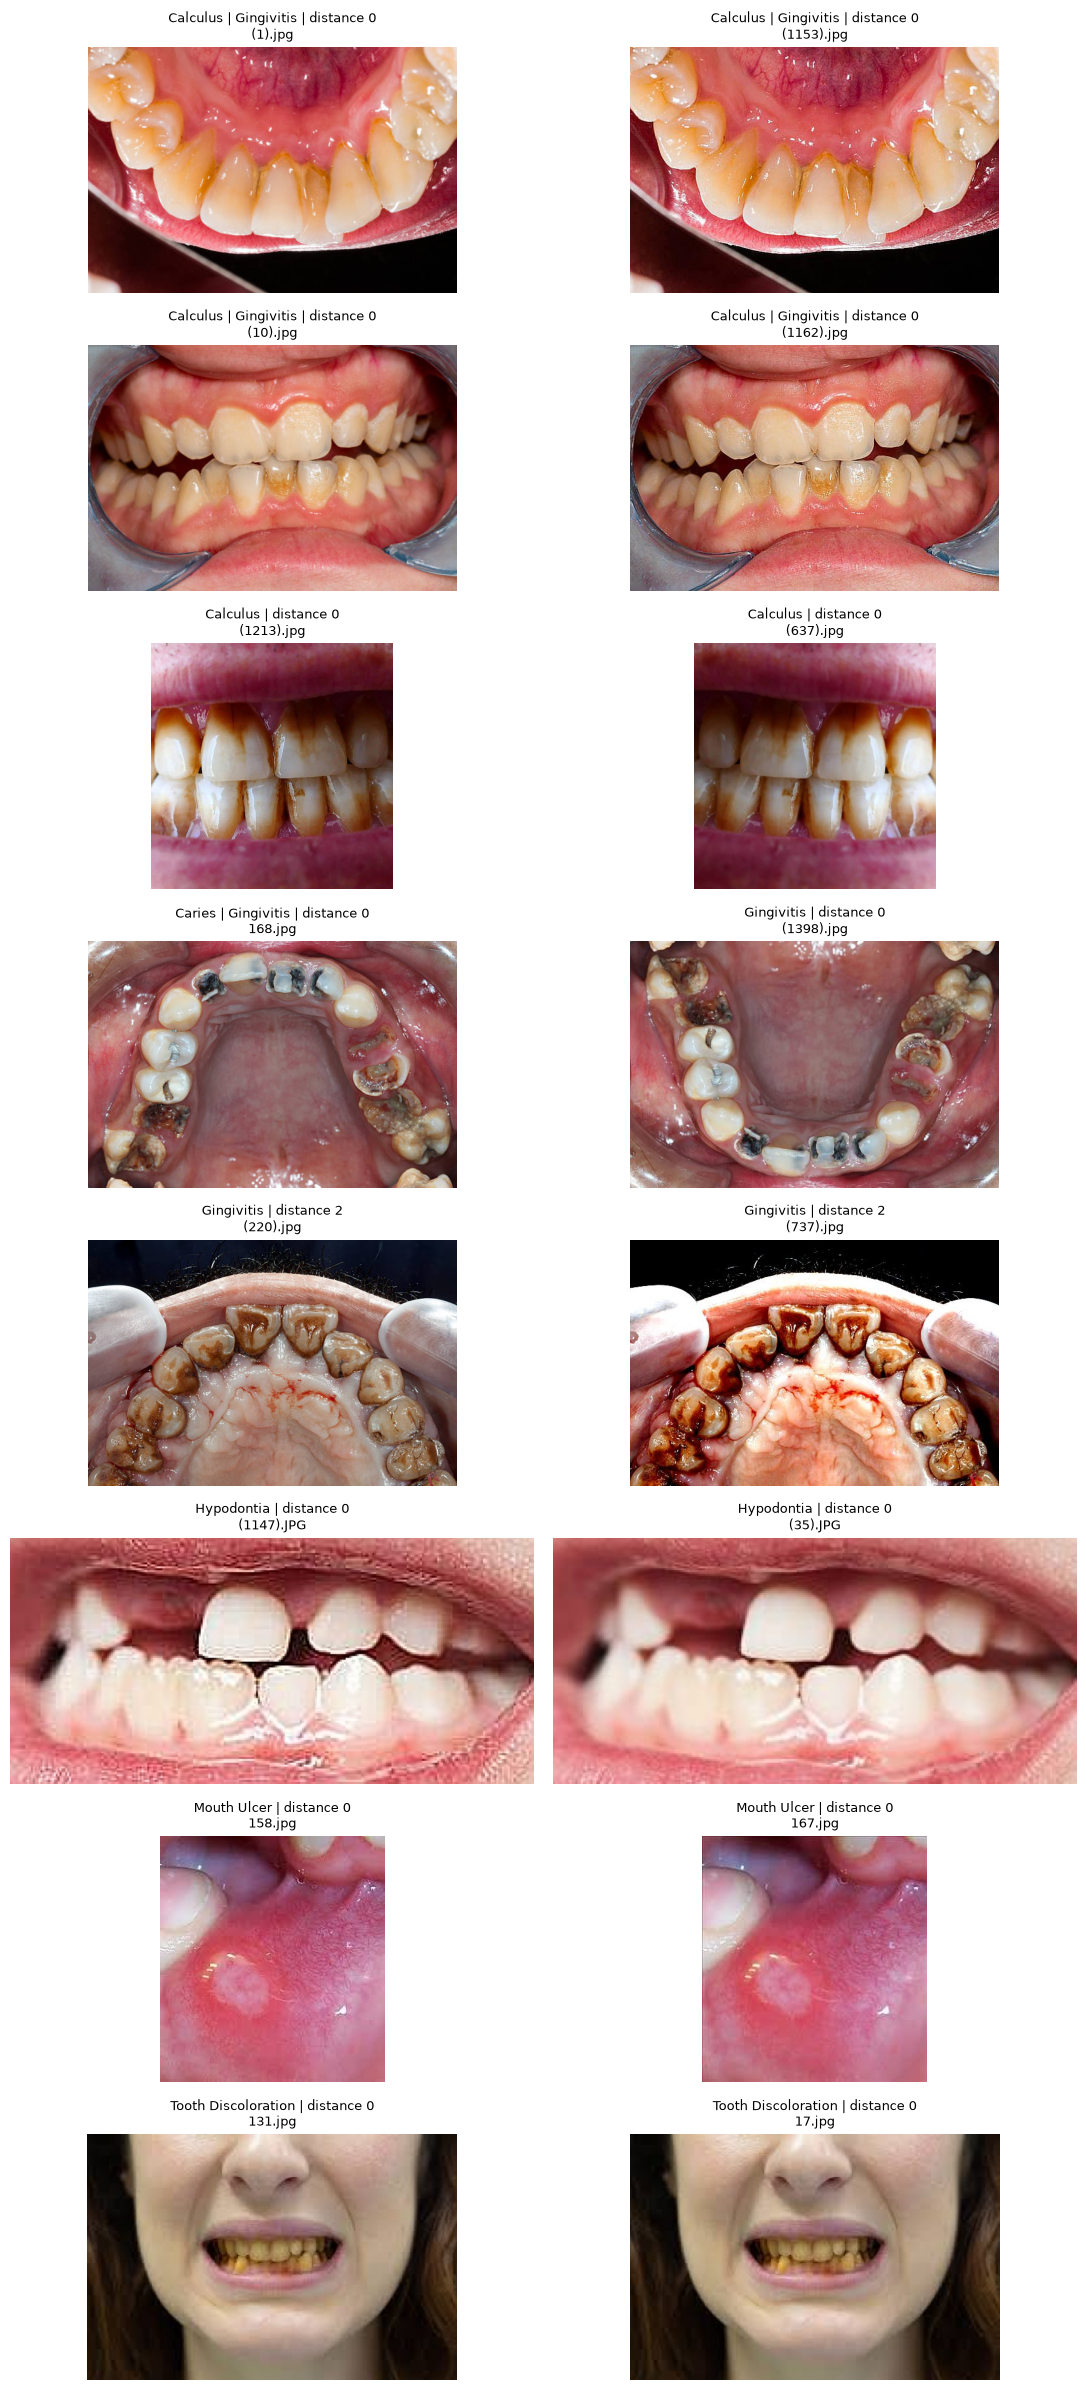

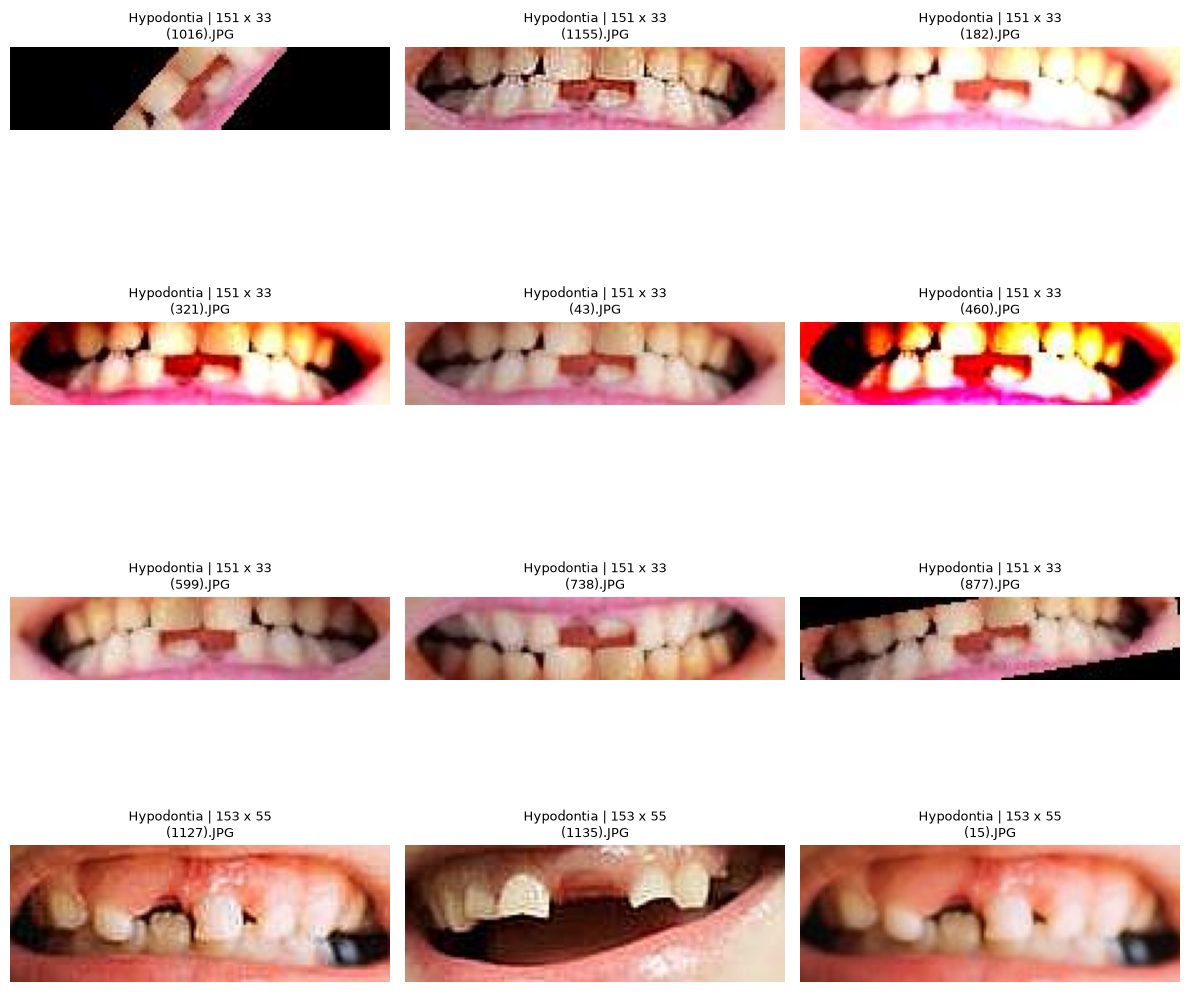

Review flagged images per class:


,flag_small,flag_extreme_aspect
class,,
Calculus,0,18
Caries,6,0
Gingivitis,0,0
Hypodontia,378,54
Mouth Ulcer,0,0
Tooth Discoloration,0,1


In [11]:
review_pool = pairs.copy()
review_pool['family_id'] = review_pool['left_hash'].map(family_by_hash)
ambiguous_pairs = review_pool.loc[review_pool['family_id'].isin(conflicting_families)].drop_duplicates('family_id').head(2)
class_samples = review_pool.groupby('left_class', group_keys=False).sample(n=1, random_state=SEED)
review_pairs = pd.concat([ambiguous_pairs, class_samples]).drop_duplicates(['left_hash','right_hash']).head(8)
labels_by_hash = source_manifest.groupby('pixel_sha256')['class'].agg(lambda values: ' | '.join(sorted(set(values)))).to_dict()
if not review_pairs.empty:
    fig, axes = plt.subplots(len(review_pairs), 2, figsize=(11, 3 * len(review_pairs)), squeeze=False)
    for row_index, (_, pair) in enumerate(review_pairs.iterrows()):
        for column, side in enumerate(['left', 'right']):
            ax = axes[row_index, column]
            ax.imshow(read_preparation_rgb(pair[f'{side}_path']))
            source_labels = labels_by_hash[pair[f'{side}_hash']]
            label_text = textwrap.fill(source_labels, width=48)
            ax.set_title(f"{label_text} | distance {pair['distance']}\n{Path(pair[f'{side}_path']).name}", fontsize=9)
            ax.axis('off')
    plt.tight_layout()
    fig.savefig(prep_dir / 'near_similarity_review.png', dpi=110)
    plt.show(); plt.close(fig)

flagged = eligible.loc[eligible['needs_geometry_review']].sort_values(['short_edge','path'])
quality_preview = flagged.head(12)
if not quality_preview.empty:
    fig, axes = plt.subplots(math.ceil(len(quality_preview) / 3), 3, figsize=(12, 3 * math.ceil(len(quality_preview) / 3)), squeeze=False)
    for ax in axes.ravel(): ax.axis('off')
    for ax, (_, row) in zip(axes.ravel(), quality_preview.iterrows()):
        ax.imshow(read_preparation_rgb(row['path']))
        ax.set_title(f"{row['class']} | {row['width']} x {row['height']}\n{Path(row['path']).name}", fontsize=9)
    plt.tight_layout()
    fig.savefig(prep_dir / 'geometry_review.png', dpi=110)
    plt.show(); plt.close(fig)
print('Review flagged images per class:')
display(eligible.groupby('class')[['flag_small','flag_extreme_aspect']].sum().reindex(CLASSES))

FAMILY_TO_VIEW = ''  # Paste a family_id here to inspect it, then rerun this cell.
if FAMILY_TO_VIEW:
    family_images = family_sources.loc[family_sources['family_id'].eq(FAMILY_TO_VIEW)].drop_duplicates('pixel_sha256').head(12)
    if family_images.empty:
        raise ValueError('Unknown family_id; copy one from family_summary.csv.')
    fig, axes = plt.subplots(math.ceil(len(family_images)/3), 3, figsize=(12, 3 * math.ceil(len(family_images)/3)), squeeze=False)
    for ax in axes.ravel(): ax.axis('off')
    for ax, (_, row) in zip(axes.ravel(), family_images.iterrows()):
        ax.imshow(read_preparation_rgb(row['path']))
        ax.set_title(f"{row['class']} | {row['width']} x {row['height']}", fontsize=9)
    plt.tight_layout(); plt.show(); plt.close(fig)

## 10. Propose a 70/15/15 split while keeping families intact

Assign whole families separately within each class. A deterministic greedy allocation places larger families first and fills the largest remaining image-count deficit. This approximates the desired **image** proportions while keeping groups intact. Random seed 42 only breaks size ties; model performance is never used to choose the split.

The checks below require all six labels in every partition, one partition per family, unique exact-image hashes, no quarantined families, and no flagged similarity link crossing partitions. These checks cover the chosen heuristic, not every possible related scene or patient. The manifest remains **PROPOSED**, pending visual review. All five models will eventually use the same frozen manifest.

In [12]:
SPLIT_FRACTIONS = {'train': 0.70, 'validation': 0.15, 'test': 0.15}
split_names = list(SPLIT_FRACTIONS)
group_table = eligible.groupby(['class','family_id']).size().rename('images').reset_index()
rng = np.random.default_rng(SEED)
assignment = {}
for label in CLASSES:
    groups = group_table.loc[group_table['class'].eq(label)].copy()
    if len(groups) < 3:
        raise ValueError(f'Too few independent families for three partitions: {label}')
    groups['tie_break'] = rng.random(len(groups))
    groups = groups.sort_values(['images','tie_break','family_id'], ascending=[False,True,True])
    targets = np.array(list(SPLIT_FRACTIONS.values())) * groups['images'].sum()
    assigned = np.zeros(3, dtype=int)
    for row in groups.itertuples(index=False):
        chosen = int(np.argmax(targets - assigned))
        assignment[row.family_id] = split_names[chosen]
        assigned[chosen] += row.images
proposal = eligible.copy()
proposal['split'] = proposal['family_id'].map(assignment)
proposal['class_idx'] = proposal['class'].map(CLASS_TO_IDX).astype(int)
proposal = proposal.sort_values(['split','class','path']).reset_index(drop=True)
assert proposal['split'].notna().all()
assert proposal['pixel_sha256'].is_unique
assert proposal['path'].is_unique
assert proposal.groupby('family_id')['split'].nunique().max() == 1
assert not proposal['family_id'].isin(conflicting_families).any()
assert not proposal['pixel_sha256'].isin(excluded_hashes).any()
counts_by_split = pd.crosstab(proposal['class'], proposal['split']).reindex(index=CLASSES, columns=split_names, fill_value=0)
assert (counts_by_split > 0).all().all(), 'Every class must have examples in all three splits.'
split_by_hash = proposal.set_index('pixel_sha256')['split'].to_dict()
left_split = pairs['left_hash'].map(split_by_hash)
right_split = pairs['right_hash'].map(split_by_hash)
crossing = pairs.loc[left_split.notna() & right_split.notna() & left_split.ne(right_split)]
assert crossing.empty, 'A flagged related pair crosses partitions.'
proposal_columns = ['path','class','class_idx','pixel_sha256','family_id','split','width','height',
                    'needs_geometry_review','flag_small','flag_extreme_aspect']
proposal[proposal_columns].to_csv(prep_dir / 'proposed_split_manifest.csv', index=False)
manifest_fingerprint = hashlib.sha256(proposal[proposal_columns].to_csv(index=False).encode('utf-8')).hexdigest()
fractions_by_class = counts_by_split.div(counts_by_split.sum(axis=1), axis=0)
print('Proposed image counts:'); display(counts_by_split)
print('Proposed proportions:'); display(fractions_by_class.round(3))
print('Total:', proposal['split'].value_counts().reindex(split_names).to_dict())
print('PASS: no exact image, family, or flagged similarity pair crosses partitions.')
print('Proposal SHA-256:', manifest_fingerprint)

Proposed image counts:


split,train,validation,test
class,,,
Calculus,296,63,63
Caries,134,29,28
Gingivitis,845,181,181
Hypodontia,851,182,182
Mouth Ulcer,170,37,36
Tooth Discoloration,119,26,25


Proposed proportions:


split,train,validation,test
class,,,
Calculus,0.701,0.149,0.149
Caries,0.702,0.152,0.147
Gingivitis,0.700,0.150,0.150
Hypodontia,0.700,0.150,0.150
Mouth Ulcer,0.700,0.152,0.148
Tooth Discoloration,0.700,0.153,0.147


Total: {'train': 2415, 'validation': 518, 'test': 515}
PASS: no exact image, family, or flagged similarity pair crosses partitions.
Proposal SHA-256: 32560253ac4ae21649eea2cfea7e64b496b06cd9ffec5443e873609725547f1e


## 11. Verify the PyTorch image pipeline and the custom CNN shape

Use a **training-only** batch. Pad each image to a square before resizing, so very wide mouth images retain their full field of view. Training adds horizontal flips and modest color changes; validation/test transforms are deterministic. ImageNet normalization is a starting preprocessing choice; later pretrained models must use the recorded normalization for their selected weights.

This cell shows a transformed training batch, computes class weights from training counts only, and checks that a small custom CNN produces six finite logits on each visible GPU using FP16 autocast. The GPU checks run one after another and do not perform distributed training, optimization, or evaluation. The demonstration DataLoader uses zero workers for easy notebook/local compatibility; the later DDP training plan uses two workers per process.

,class,training_images,loss_weight
0,Calculus,296,1.359797
1,Caries,134,3.003731
2,Gingivitis,845,0.476331
3,Hypodontia,851,0.472973
4,Mouth Ulcer,170,2.367647
5,Tooth Discoloration,119,3.382353


Training batch: (8, 3, 224, 224) | labels: [0, 3, 3, 3, 2, 5, 0, 1]


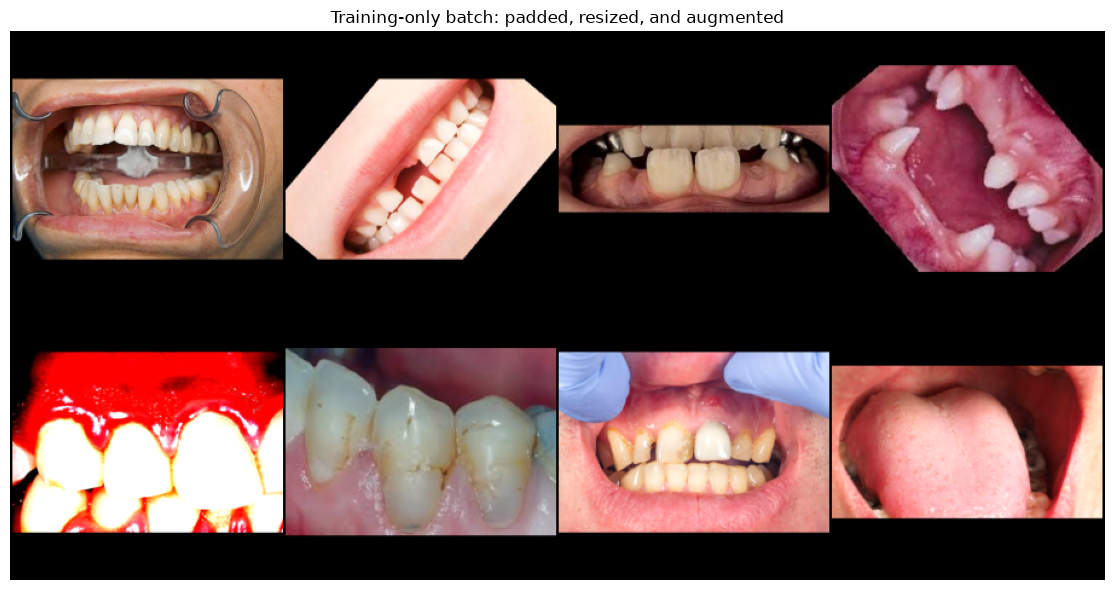

Custom CNN parameters: 94,246
CNN forward check passed: {'device': 'cuda:0', 'shape': [8, 6], 'finite': True, 'precision': 'torch.float16', 'trained': False}
CNN forward check passed: {'device': 'cuda:1', 'shape': [8, 6], 'finite': True, 'precision': 'torch.float16', 'trained': False}


In [13]:
class PadToSquare:
    def __call__(self, image):
        width, height = image.size
        side = max(width, height)
        left, top = (side - width) // 2, (side - height) // 2
        return ImageOps.expand(image, (left, top, side-width-left, side-height-top), fill=(0,0,0))

IMAGE_SIZE = 224
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)
train_transform = transforms.Compose([
    PadToSquare(), transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.05),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
evaluation_transform = transforms.Compose([
    PadToSquare(), transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class OralImageDataset(Dataset):
    def __init__(self, frame, transform, source_root=None, archive_path=None):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
        self.source_root = Path(source_root) if source_root is not None else None
        self.archive_path = Path(archive_path) if archive_path is not None else None
    def __len__(self): return len(self.frame)
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        if self.source_root is not None:
            content = (self.source_root / row['path']).read_bytes()
        else:
            with ZipFile(self.archive_path) as source:
                content = source.read(row['path'])
        with Image.open(io.BytesIO(content)) as image:
            image = ImageOps.exif_transpose(image).convert('RGB')
        return self.transform(image), int(row['class_idx'])

training_rows = proposal.loc[proposal['split'].eq('train')]
train_counts = training_rows['class_idx'].value_counts().reindex(range(len(CLASSES)), fill_value=0)
assert (train_counts > 0).all()
class_weights = torch.tensor(len(training_rows) / (len(CLASSES) * train_counts.to_numpy()), dtype=torch.float32)
display(pd.DataFrame({'class': CLASSES, 'training_images': train_counts.to_numpy(), 'loss_weight': class_weights.numpy()}))
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
train_dataset = OralImageDataset(training_rows, train_transform, data_root, zip_path)
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=0,
                          pin_memory=torch.cuda.is_available(), generator=torch.Generator().manual_seed(SEED))
images, labels = next(iter(train_loader))
assert tuple(images.shape[1:]) == (3,224,224)
assert torch.isfinite(images).all() and labels.min() >= 0 and labels.max() < 6
print('Training batch:', tuple(images.shape), '| labels:', labels.tolist())
unscaled = (images * torch.tensor(STD)[None,:,None,None] + torch.tensor(MEAN)[None,:,None,None]).clamp(0,1)
grid = torchvision.utils.make_grid(unscaled, nrow=4)
plt.figure(figsize=(12,6)); plt.imshow(grid.permute(1,2,0)); plt.axis('off')
plt.title('Training-only batch: padded, resized, and augmented'); plt.tight_layout()
plt.savefig(prep_dir / 'pytorch_training_batch.png', dpi=110); plt.show(); plt.close()

class OralBaselineCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        layers = []
        channels = 3
        for out_channels in [32,64,128]:
            layers.extend([nn.Conv2d(channels,out_channels,3,padding=1,bias=False),
                           nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True), nn.MaxPool2d(2)])
            channels = out_channels
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Dropout(0.3),nn.Linear(128,num_classes))
    def forward(self, x): return self.classifier(self.features(x))

parameter_count = sum(parameter.numel() for parameter in OralBaselineCNN().parameters())
print('Custom CNN parameters:', f'{parameter_count:,}')
devices = [torch.device(f'cuda:{i}') for i in range(torch.cuda.device_count())] if torch.cuda.is_available() else [torch.device('cpu')]
cnn_checks = []
for device in devices:
    model = OralBaselineCNN().to(device).eval()
    with torch.inference_mode(), torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type=='cuda'):
        logits = model(images.to(device, non_blocking=True))
    assert tuple(logits.shape) == (len(images), 6) and torch.isfinite(logits).all().item()
    cnn_checks.append({'device':str(device), 'shape':list(logits.shape), 'finite':True,
                       'precision':str(logits.dtype), 'trained':False})
    print('CNN forward check passed:', cnn_checks[-1])
    del model, logits
# Keep raw logits for future CrossEntropyLoss. A forward check has no accuracy score.

## 12. Lock this initial experiment split and verify the base weights

This locks the computed split for this run, with the dataset limitations recorded. It does not claim a complete clinical or visual review. Changing group links/exclusions later requires a new experiment directory. The same manifest is shared across all trials; class weights use training counts only.

The four official checkpoints are downloaded and SHA-256 checked once, before child processes start. Missing internet or incorrect attached weights fail here, before long training. `RESUME_FROM` can point to a previous notebook's `oral_training` folder attached as an input; default `None` starts the first experiment. Resuming recovers completed epochs, optimizer/scaler state, and completed trials, but does not promise identical augmentation RNG after a session change.

In [14]:
WEIGHT_SPECS = [{'model': 'ResNet50', 'architecture': 'resnet50', 'filename': 'resnet50-11ad3fa6.pth', 'url': 'https://download.pytorch.org/models/resnet50-11ad3fa6.pth', 'bytes': 102540417, 'sha256': '11ad3fa62ca79e40addfd354a8ec4b7c75143b3038b8d2a807fbc68deab379ca', 'weights_enum': 'ResNet50_Weights.IMAGENET1K_V2'}, {'model': 'EfficientNet-B0', 'architecture': 'efficientnet_b0', 'filename': 'efficientnet_b0_rwightman-7f5810bc.pth', 'url': 'https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth', 'bytes': 21444401, 'sha256': '7f5810bc96def8f7552d5b7e68d53c4786f81167d28291b21c0d90e1fca14934', 'weights_enum': 'EfficientNet_B0_Weights.IMAGENET1K_V1'}, {'model': 'MobileNetV3-Large', 'architecture': 'mobilenet_v3_large', 'filename': 'mobilenet_v3_large-5c1a4163.pth', 'url': 'https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth', 'bytes': 22132113, 'sha256': '5c1a416349c4cf298f2a6a5e2600ed0ee55e604713578f5e74e6bc8bcaef7997', 'weights_enum': 'MobileNet_V3_Large_Weights.IMAGENET1K_V2'}, {'model': 'ResNet101', 'architecture': 'resnet101', 'filename': 'resnet101-cd907fc2.pth', 'url': 'https://download.pytorch.org/models/resnet101-cd907fc2.pth', 'bytes': 178814045, 'sha256': 'cd907fc2a0de2292b2ba2b27d2216bc672d84632d1cf20058d01c0c03b5e020e', 'weights_enum': 'ResNet101_Weights.IMAGENET1K_V2'}]
import shutil, urllib.request, gc

RESUME_FROM = None  # Optional Path('/kaggle/input/.../oral_training') for an interrupted earlier run.
EPOCHS_CUSTOM = 15
EPOCHS_PRETRAINED = 10
PATIENCE = 3
MAX_TRAINING_HOURS = 9

assert ON_KAGGLE, 'This full training notebook targets Kaggle; use the inspection notebook for local ZIP work.'
assert torch.cuda.device_count() == 2 and all('T4' in torch.cuda.get_device_name(i) for i in range(2))
assert PHASH_ALGORITHM == 'dct32_low8_rgb_dihedral_v2'
run_dir = Path('/kaggle/working/oral_training')
run_dir.mkdir(parents=True, exist_ok=True)
if RESUME_FROM is not None:
    previous = Path(RESUME_FROM)
    if not (previous/'experiment_config.json').is_file():
        raise FileNotFoundError('RESUME_FROM must point to the prior oral_training output folder.')
    shutil.copytree(previous,run_dir,dirs_exist_ok=True)
if shutil.disk_usage(run_dir).free < 4 * 2**30:
    raise RuntimeError('At least 4 GiB of output space is needed for the planned checkpoints.')

manifest_path = run_dir/'split_manifest.csv'
manifest_bytes = proposal[proposal_columns].to_csv(index=False,lineterminator='\n').encode('utf-8')
if manifest_path.exists() and manifest_path.read_bytes() != manifest_bytes:
    raise RuntimeError('An existing experiment uses a different split. Preserve it and start a new experiment directory.')
manifest_path.write_bytes(manifest_bytes)
training_manifest_sha = hashlib.sha256(manifest_bytes).hexdigest()
(run_dir/'class_to_idx.json').write_text(json.dumps(CLASS_TO_IDX,indent=2))
(run_dir/'data_policy.json').write_text(json.dumps({
    'status':'FIXED_INITIAL_EXPERIMENT', 'manifest_sha256':training_manifest_sha,
    'source_fingerprint':source_fingerprint,'phash_algorithm':PHASH_ALGORITHM,'orientations':VARIANTS,
    'perceptual_pairs':len(pairs),'eligible_images':len(proposal),'families':int(proposal['family_id'].nunique()),
    'label_conflict_candidates_quarantined':int(audit_candidates['family_label_conflict'].sum()),
    'geometry_flagged_eligible_images':int(eligible['needs_geometry_review'].sum()),
    'visual_review':'120 local samples plus transformation-match sheets inspected; not every image clinically reviewed.',
    'patient_independence':'Unverified','clinical_labels_validated':False,
    'manual_links':MANUAL_FAMILY_LINKS,'manual_exclusions':EXCLUDE_PATHS},indent=2))

base_dir = run_dir/'base_weights';base_dir.mkdir(exist_ok=True)
def file_digest(path):
    value=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(1024*1024),b''): value.update(block)
    return value.hexdigest()
weights_ready={}
for specification in WEIGHT_SPECS:
    target=base_dir/specification['filename']
    if not (target.is_file() and file_digest(target)==specification['sha256']):
        available=list(Path('/kaggle/input').rglob(specification['filename']))
        correct=next((candidate for candidate in available if file_digest(candidate)==specification['sha256']),None)
        if correct is not None:
            shutil.copyfile(correct,target)
        else:
            print('Downloading official weights:',specification['architecture'],flush=True)
            temporary=target.with_suffix('.download')
            try:
                with urllib.request.urlopen(specification['url'],timeout=60) as response,temporary.open('wb') as destination:
                    shutil.copyfileobj(response,destination)
            except Exception as error:
                raise RuntimeError('Enable Internet in Kaggle or attach the exact official .pth files listed above, then rerun this cell.') from error
            if file_digest(temporary)!=specification['sha256']:
                raise RuntimeError('Downloaded checkpoint failed its SHA-256 check: '+target.name)
            temporary.replace(target)
    weights_ready[specification['architecture']]={**specification,'path':str(target)}
    print('Verified:',target.name,flush=True)

trials=[]
for name in ['custom_cnn','efficientnet_b0','mobilenet_v3_large','resnet50','resnet101']:
    for trial_index,(lr,dropout) in enumerate([(1e-3,0.3),(3e-4,0.4)],1):
        trials.append({'id':name+'_trial'+str(trial_index),'model':name,'lr':lr,'dropout':dropout,
            'weight_decay':1e-4,'epochs':EPOCHS_CUSTOM if name=='custom_cnn' else EPOCHS_PRETRAINED,
            'batch_size_per_gpu':16 if name=='resnet101' else 32})
config={'manifest':str(manifest_path),'manifest_sha256':training_manifest_sha,'data_root':str(data_root),
        'output':str(run_dir),'classes':CLASSES,'seed':SEED,'weights':weights_ready,'trials':trials,
        'image_size':224,'workers_per_rank':2,'patience':PATIENCE,'max_training_hours':MAX_TRAINING_HOURS}
config_path=run_dir/'experiment_config.json'
config_path.write_text(json.dumps(config,indent=2))
(run_dir/'runtime.json').write_text(json.dumps({'python':platform.python_version(),'torch':str(torch.__version__),
    'torchvision':str(torchvision.__version__),'gpu_names':[torch.cuda.get_device_name(i) for i in range(2)],
    'cuda_build':torch.version.cuda,'world_size':2,'library_versions':library_versions, 'local_package_pins':LOCAL_PACKAGE_PINS, 'local_runtime_reference':LOCAL_RUNTIME_VERSIONS},indent=2))
display(pd.DataFrame(trials))
print('Ready:',len(trials),'trials / five models. Weights verified. Split locked for this initial experiment.')

Verified: resnet50-11ad3fa6.pth
Verified: efficientnet_b0_rwightman-7f5810bc.pth
Verified: mobilenet_v3_large-5c1a4163.pth
Verified: resnet101-cd907fc2.pth


,id,model,lr,dropout,weight_decay,epochs,batch_size_per_gpu
0,custom_cnn_trial1,custom_cnn,0.0010,0.3,0.0001,15,32
1,custom_cnn_trial2,custom_cnn,0.0003,0.4,0.0001,15,32
2,efficientnet_b0_trial1,efficientnet_b0,0.0010,0.3,0.0001,10,32
3,efficientnet_b0_trial2,efficientnet_b0,0.0003,0.4,0.0001,10,32
4,mobilenet_v3_large_trial1,mobilenet_v3_large,0.0010,0.3,0.0001,10,32
5,mobilenet_v3_large_trial2,mobilenet_v3_large,0.0003,0.4,0.0001,10,32
6,resnet50_trial1,resnet50,0.0010,0.3,0.0001,10,32
7,resnet50_trial2,resnet50,0.0003,0.4,0.0001,10,32
8,resnet101_trial1,resnet101,0.0010,0.3,0.0001,10,16
9,resnet101_trial2,resnet101,0.0003,0.4,0.0001,10,16


Ready: 10 trials / five models. Weights verified. Split locked for this initial experiment.


## 13. Write the embedded trainer and run a genuine two-GPU preflight

The code below writes its embedded training program to the output folder; it needs no local project files. `torchrun` launches one process per T4. Every model receives one real training batch and completes loss computation, gradient synchronization, backward propagation, and an optimizer step. These disposable smoke-test models are discarded; they are not reported as trained results.

Training uses FP16 autocast with gradient scaling, weighted cross-entropy, AdamW, cosine learning-rate scheduling, and early stopping. Pretrained backbones fine-tune at one tenth of the classifier learning rate. Validation runs on rank zero over the complete non-padded validation set; only rank zero writes shared results.

In [15]:
TRAINER_SOURCE = '"""Two-process PyTorch experiment runner, embedded in the Kaggle Run All notebook."""\n\nimport argparse\nimport datetime\nimport hashlib\nimport json\nimport os\nfrom pathlib import Path\nimport random\nimport time\n\nimport numpy as np\nimport pandas as pd\nfrom PIL import Image, ImageOps\nfrom sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score\nimport torch\nimport torch.distributed as dist\nfrom torch import nn\nfrom torch.nn.parallel import DistributedDataParallel as DDP\nfrom torch.utils.data import DataLoader, Dataset, DistributedSampler\nfrom torchvision import models, transforms\n\n\nVERSION = "oral-ddp-20261029-v2"\n\n\ndef write_json(path, value):\n    path = Path(path)\n    temporary = path.with_suffix(path.suffix + ".tmp")\n    temporary.write_text(json.dumps(value, indent=2), encoding="utf-8")\n    temporary.replace(path)\n\n\ndef save_checkpoint(path, value):\n    temporary = Path(str(path) + ".tmp")\n    torch.save(value, temporary)\n    temporary.replace(path)\n\n\nclass PadSquare:\n    def __call__(self, image):\n        width, height = image.size\n        side = max(width, height)\n        left, top = (side - width) // 2, (side - height) // 2\n        return ImageOps.expand(image, (left, top, side-width-left, side-height-top), fill=0)\n\n\nclass OralCNN(nn.Module):\n    def __init__(self, classes=6, dropout=0.3):\n        super().__init__()\n        blocks = []\n        incoming = 3\n        for outgoing in [32, 64, 128]:\n            blocks += [nn.Conv2d(incoming, outgoing, 3, padding=1, bias=False), nn.BatchNorm2d(outgoing),\n                       nn.ReLU(inplace=True), nn.MaxPool2d(2)]\n            incoming = outgoing\n        self.features = nn.Sequential(*blocks)\n        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(128, classes))\n\n    def forward(self, images):\n        return self.classifier(self.features(images))\n\n\ndef create_model(name, dropout, weights_spec, pretrained=True):\n    if name == "custom_cnn":\n        return OralCNN(dropout=dropout)\n    model = models.get_model(name, weights=None)\n    if pretrained:\n        state = torch.load(weights_spec[name]["path"], map_location="cpu", weights_only=True)\n        model.load_state_dict(state, strict=True)\n    if name.startswith("resnet"):\n        model.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.fc.in_features, 6))\n    else:\n        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, 6)\n        for layer in model.classifier.modules():\n            if isinstance(layer, nn.Dropout):\n                layer.p = dropout\n    return model\n\n\ndef image_transform(name, weights_spec, image_size, training):\n    if name == "custom_cnn":\n        mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]\n        interpolation = transforms.InterpolationMode.BILINEAR\n    else:\n        recipe = models.get_weight(weights_spec[name]["weights_enum"]).transforms()\n        mean, std, interpolation = recipe.mean, recipe.std, recipe.interpolation\n    # Adapt geometry to this task while preserving each weight\'s normalization/interpolation.\n    steps = [PadSquare(), transforms.Resize((image_size, image_size), interpolation=interpolation)]\n    if training:\n        steps += [transforms.RandomHorizontalFlip(0.5), transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.05)]\n    steps += [transforms.ToTensor(), transforms.Normalize(mean, std)]\n    return transforms.Compose(steps), {"size": image_size, "mean": mean, "std": std,\n                                      "interpolation": str(interpolation), "geometry": "pad_square_black_then_resize"}\n\n\nclass OralDataset(Dataset):\n    def __init__(self, frame, root, transform):\n        self.paths = frame["path"].tolist()\n        self.labels = frame["class_idx"].astype(int).tolist()\n        self.root, self.transform = Path(root), transform\n\n    def __len__(self):\n        return len(self.paths)\n\n    def __getitem__(self, index):\n        with Image.open(self.root / self.paths[index]) as image:\n            image = ImageOps.exif_transpose(image).convert("RGB")\n        return self.transform(image), self.labels[index]\n\n\ndef seed_worker(worker_id):\n    worker_seed = torch.initial_seed() % 2**32\n    np.random.seed(worker_seed)\n    random.seed(worker_seed)\n\n\ndef seed_all(seed):\n    random.seed(seed)\n    np.random.seed(seed % 2**32)\n    torch.manual_seed(seed)\n    if torch.cuda.is_available():\n        torch.cuda.manual_seed_all(seed)\n\n\ndef loader(frame, root, transform, batch, workers, device, sampler=None, seed=42):\n    options = dict(batch_size=batch, num_workers=workers, pin_memory=device.type == "cuda",\n                   sampler=sampler, shuffle=False, worker_init_fn=seed_worker,\n                   generator=torch.Generator().manual_seed(seed))\n    if workers:\n        options.update(persistent_workers=True, multiprocessing_context="spawn", prefetch_factor=2)\n    return DataLoader(OralDataset(frame, root, transform), **options)\n\n\ndef evaluate(model, batches, device):\n    model.eval()\n    truths, probabilities, total_loss, count = [], [], 0.0, 0\n    with torch.inference_mode():\n        for images, labels in batches:\n            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)\n            # Score in FP32: a few heavily processed inputs can overflow FP16 evaluation activations.\n            logits = model(images)\n            loss = nn.functional.cross_entropy(logits, labels, reduction="sum")\n            if not torch.isfinite(logits).all().item():\n                raise FloatingPointError("Non-finite evaluation logits")\n            total_loss += loss.item()\n            count += len(labels)\n            truths.extend(labels.cpu().tolist())\n            probabilities.extend(logits.float().softmax(1).cpu().tolist())\n    predictions = np.asarray(probabilities).argmax(axis=1)\n    metrics = {"loss": total_loss/count, "accuracy": float(accuracy_score(truths, predictions)),\n               "macro_f1": float(f1_score(truths, predictions, labels=list(range(6)), average="macro", zero_division=0))}\n    return metrics, truths, predictions, probabilities\n\n\ndef make_optimizer(model, name, trial):\n    if name == "custom_cnn":\n        groups = [{"params": model.parameters(), "lr": trial["lr"]}]\n    else:\n        head = model.fc if name.startswith("resnet") else model.classifier\n        head_ids = {id(p) for p in head.parameters()}\n        groups = [{"params": [p for p in model.parameters() if id(p) not in head_ids], "lr": trial["lr"] * 0.1},\n                  {"params": list(head.parameters()), "lr": trial["lr"]}]\n    return torch.optim.AdamW(groups, weight_decay=trial["weight_decay"])\n\n\ndef synchronize(value, rank, world):\n    if world == 1:\n        return value\n    message = [value if rank == 0 else None]\n    dist.broadcast_object_list(message, src=0)\n    return message[0]\n\n\ndef barrier(world):\n    if world > 1:\n        dist.barrier()\n\n\ndef run_trial(config, trial, frame, device, rank, world, deadline, preflight=False):\n    name = trial["model"]\n    run_dir = Path(config["output"]) / trial["id"]\n    run_dir.mkdir(parents=True, exist_ok=True)\n    signature = hashlib.sha256(json.dumps({"version": VERSION, "trial": trial,\n        "manifest": config["manifest_sha256"], "image_size": config["image_size"],\n        "classes": config["classes"], "weights": {k:v["sha256"] for k,v in config["weights"].items()}}, sort_keys=True).encode()).hexdigest()\n    completed = None\n    if rank == 0 and not preflight and (run_dir / "result.json").is_file():\n        completed = json.loads((run_dir / "result.json").read_text())\n        if completed["signature"] != signature:\n            raise RuntimeError(f"Existing output configuration differs: {run_dir}; use a new experiment directory.")\n    completed = synchronize(completed, rank, world)\n    if completed is not None:\n        if rank == 0:\n            print("Already completed:", trial["id"], flush=True)\n        return completed, False\n\n    seed_all(config["seed"] + rank)\n    model = create_model(name, trial["dropout"], config["weights"]).to(device)\n    optimizer = make_optimizer(model, name, trial)\n    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=trial["epochs"])\n    scaler = torch.amp.GradScaler("cuda", init_scale=1024.0, enabled=device.type == "cuda")\n    train_frame = frame.loc[frame["split"].eq("train")].reset_index(drop=True)\n    val_frame = frame.loc[frame["split"].eq("validation")].reset_index(drop=True)\n    train_transform, preprocessing = image_transform(name, config["weights"], config["image_size"], True)\n    val_transform, _ = image_transform(name, config["weights"], config["image_size"], False)\n    sampler = DistributedSampler(train_frame, num_replicas=world, rank=rank, shuffle=True, seed=config["seed"])\n    batch_size = trial["batch_size_per_gpu"]\n    train_batches = loader(train_frame, config["data_root"], train_transform, batch_size, config["workers_per_rank"], device, sampler, config["seed"]+rank)\n    # Rank zero evaluates the entire non-padded validation set; no distributed evaluation duplicates.\n    val_batches = loader(val_frame, config["data_root"], val_transform, batch_size, 0, device) if rank == 0 else None\n    counts = train_frame["class_idx"].value_counts().reindex(range(6), fill_value=0).to_numpy()\n    if not (counts > 0).all():\n        raise ValueError("A training class is missing")\n    weights = torch.tensor(len(train_frame)/(6*counts), dtype=torch.float32, device=device)\n    criterion = nn.CrossEntropyLoss(weight=weights)\n    start_epoch, best, stale, history, previous_seconds = 0, -1.0, 0, [], 0.0\n    latest_path = run_dir / "latest.pt"\n    if latest_path.is_file() and not preflight:\n        checkpoint = torch.load(latest_path, map_location="cpu", weights_only=True)\n        if checkpoint["signature"] != signature:\n            raise RuntimeError("Resume signature differs; choose a new output directory")\n        model.load_state_dict(checkpoint["state_dict"])\n        optimizer.load_state_dict(checkpoint["optimizer"])\n        scheduler.load_state_dict(checkpoint["scheduler"])\n        scaler.load_state_dict(checkpoint["scaler"])\n        start_epoch, best, stale = checkpoint["epoch"]+1, checkpoint["best"], checkpoint["stale"]\n        history, previous_seconds = checkpoint["history"], checkpoint["training_seconds"]\n        if stale >= config["patience"]:\n            start_epoch = trial["epochs"]\n    if world > 1:\n        model = DDP(model, device_ids=[device.index] if device.type == "cuda" else None)\n    base = model.module if isinstance(model, DDP) else model\n    start_time = time.perf_counter()\n    interrupted = False\n    epochs = 1 if preflight else trial["epochs"]\n    for epoch in range(start_epoch, epochs):\n        epoch_start = time.perf_counter()\n        seed_all(config["seed"] + epoch*world + rank)\n        sampler.set_epoch(epoch)\n        model.train()\n        total_loss, total_count, optimizer_updates = 0.0, 0, 0\n        probe = base.fc[-1].weight if name.startswith("resnet") else base.classifier[-1].weight\n        probe_before = probe.detach().clone() if preflight else None\n        for batch_index, (images, labels) in enumerate(train_batches):\n            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)\n            for attempt in range(8 if preflight else 1):\n                optimizer.zero_grad(set_to_none=True)\n                with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):\n                    logits = model(images)\n                    loss = criterion(logits, labels)\n                if not torch.isfinite(loss).item():\n                    raise FloatingPointError(f"Non-finite loss in {trial[\'id\']}")\n                previous_scale = scaler.get_scale()\n                scaler.scale(loss).backward()\n                scaler.unscale_(optimizer)\n                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)\n                scaler.step(optimizer)\n                scaler.update()\n                accepted = scaler.get_scale() >= previous_scale\n                optimizer_updates += int(accepted)\n                if accepted:\n                    break\n            total_loss += loss.item() * len(labels)\n            total_count += len(labels)\n            if preflight or (config.get("debug_max_batches") and batch_index+1 >= config["debug_max_batches"]):\n                break\n        totals = torch.tensor([total_loss, total_count, optimizer_updates], device=device, dtype=torch.float64)\n        if world > 1:\n            dist.all_reduce(totals)\n        barrier(world)\n        if totals[2].item() == 0:\n            raise FloatingPointError("No optimizer update succeeded; reduce the initial AMP scale or inspect gradients before training.")\n        if preflight:\n            if torch.equal(probe_before, probe.detach()):\n                raise RuntimeError("Preflight did not change the classifier weights")\n            base.eval()\n            with torch.inference_mode():\n                check_logits = base(images)\n            if not torch.isfinite(check_logits).all().item():\n                raise FloatingPointError("Non-finite FP32 logits after the preflight optimizer update")\n            if rank == 0:\n                print("PREFLIGHT PASS:", name, "world_size", world, "classifier weights changed; finite loss", float(totals[0]/totals[1]), flush=True)\n            break\n        if rank == 0:\n            validation, _, _, _ = evaluate(base, val_batches, device)\n            improved = validation["macro_f1"] > best + 1e-6\n            if improved:\n                best, stale = validation["macro_f1"], 0\n                save_checkpoint(run_dir / "best.pt", {"state_dict":base.state_dict(), "signature":signature,\n                    "trial":trial, "class_to_idx":{name:i for i,name in enumerate(config["classes"])},\n                    "preprocessing":preprocessing, "validation":validation, "epoch":epoch+1,\n                    "manifest_sha256":config["manifest_sha256"], "weights":config["weights"].get(name), "version":VERSION})\n            else:\n                stale += 1\n            scheduler.step()\n            row = {"epoch":epoch+1,"train_loss":float(totals[0]/totals[1]),"validation_loss":validation["loss"],\n                   "validation_accuracy":validation["accuracy"],"validation_macro_f1":validation["macro_f1"],\n                   "optimizer_updates":int(totals[2].item()/world),\n                   "epoch_seconds":time.perf_counter()-epoch_start}\n            history.append(row)\n            save_checkpoint(latest_path, {"state_dict":base.state_dict(),"signature":signature,"optimizer":optimizer.state_dict(),\n                "scheduler":scheduler.state_dict(),"scaler":scaler.state_dict(),"epoch":epoch,"best":best,"stale":stale,\n                "history":history,"training_seconds":previous_seconds+time.perf_counter()-start_time})\n            pd.DataFrame(history).to_csv(run_dir / "history.csv", index=False)\n            interrupted = time.monotonic() >= deadline and stale < config["patience"] and epoch+1 < epochs\n            stop = stale >= config["patience"] or interrupted\n            print(trial["id"], json.dumps(row), "[checkpoint saved]", flush=True)\n            state = [stop,interrupted,best,stale]\n        else:\n            scheduler.step()\n            state = None\n        stop, interrupted, best, stale = synchronize(state, rank, world)\n        if stop:\n            break\n    barrier(world)\n    if preflight:\n        return None, False\n    result = None\n    if rank == 0 and not interrupted:\n        checkpoint = torch.load(run_dir / "best.pt",map_location="cpu",weights_only=True)\n        result = {"id":trial["id"],"model":name,"signature":signature,"trial":trial,\n                  "best_validation_macro_f1":best,"best_epoch":checkpoint["epoch"],\n                  "validation_accuracy":checkpoint["validation"]["accuracy"],\n                  "epochs_run":len(history),"training_seconds":previous_seconds+time.perf_counter()-start_time,\n                  "parameters":sum(p.numel() for p in base.parameters()),"best_checkpoint":str(run_dir / "best.pt")}\n        write_json(run_dir / "result.json",result)\n    result = synchronize(result,rank,world)\n    return result, interrupted\n\n\ndef final_reports(config, results, frame, device):\n    output = Path(config["output"])\n    trials = pd.DataFrame([{k:v for k,v in result.items() if k != "trial"} for result in results])\n    trials.to_csv(output / "all_validation_trials.csv",index=False)\n    winners = [max([r for r in results if r["model"] == name], key=lambda r:r["best_validation_macro_f1"])\n               for name in dict.fromkeys(trial["model"] for trial in config["trials"])]\n    winner = max(winners,key=lambda result:result["best_validation_macro_f1"])\n    # This decision is recorded before looking at test predictions.\n    write_json(output / "selected_model.json",{"criterion":"validation_macro_f1","trial":winner["id"],\n               "model":winner["model"],"best_checkpoint":winner["best_checkpoint"],"selected_before_test":True})\n    rows = []\n    test_frame = frame.loc[frame["split"].eq("test")].reset_index(drop=True)\n    for result in winners:\n        checkpoint = torch.load(result["best_checkpoint"],map_location="cpu",weights_only=True)\n        cache_file = output / (result["id"]+"_test_metrics.json")\n        cache_signature = hashlib.sha256(Path(result["best_checkpoint"]).read_bytes()).hexdigest()\n        if cache_file.is_file():\n            saved = json.loads(cache_file.read_text())\n            if saved["checkpoint_sha256"] == cache_signature:\n                rows.append(saved)\n                continue\n        model = create_model(result["model"],result["trial"]["dropout"],config["weights"],pretrained=False).to(device)\n        model.load_state_dict(checkpoint["state_dict"])\n        transform, _ = image_transform(result["model"],config["weights"],config["image_size"],False)\n        batches = loader(test_frame,config["data_root"],transform,32,0,device)\n        metrics, truths, predicted, probabilities = evaluate(model,batches,device)\n        report = classification_report(truths,predicted,labels=list(range(6)),target_names=config["classes"],zero_division=0,output_dict=True)\n        pd.DataFrame(report).T.to_csv(output / (result["id"]+"_per_class.csv"))\n        pd.DataFrame(confusion_matrix(truths,predicted,labels=list(range(6))),index=config["classes"],columns=config["classes"]).to_csv(output / (result["id"]+"_confusion_matrix.csv"))\n        predictions = test_frame[["path","class","class_idx","family_id"]].copy()\n        predictions["prediction_idx"] = predicted\n        for index,label in enumerate(config["classes"]):\n            predictions["score_"+label] = np.asarray(probabilities)[:,index]\n        predictions.to_csv(output / (result["id"]+"_test_predictions.csv"),index=False)\n        model.eval()\n        dummy = torch.zeros(1,3,config["image_size"],config["image_size"],device=device)\n        times = []\n        with torch.inference_mode():\n            for index in range(35):\n                if device.type == "cuda": torch.cuda.synchronize(device)\n                start = time.perf_counter()\n                model(dummy)\n                if device.type == "cuda": torch.cuda.synchronize(device)\n                if index >= 10: times.append((time.perf_counter()-start)*1000)\n        saved = {"model":result["model"],"trial":result["id"],"validation_macro_f1":result["best_validation_macro_f1"],\n                 "test_macro_f1":metrics["macro_f1"],"test_accuracy":metrics["accuracy"],\n                 "parameters":result["parameters"],"training_seconds":result["training_seconds"],\n                 "checkpoint_MB":Path(result["best_checkpoint"]).stat().st_size/1e6,\n                 "batch1_model_only_median_ms":float(np.median(times)),"batch1_model_only_p95_ms":float(np.percentile(times,95)),\n                 "latency_device":str(device),"checkpoint_sha256":cache_signature}\n        saved["evaluation_and_latency_precision"] = "fp32"\n        write_json(cache_file,saved)\n        rows.append(saved)\n        del model,checkpoint\n        if device.type == "cuda": torch.cuda.empty_cache()\n    pd.DataFrame(rows).sort_values("validation_macro_f1",ascending=False).to_csv(output / "model_comparison.csv",index=False)\n    write_json(output / "experiment_status.json",{"status":"COMPLETE","trials":len(results),"models":len(winners),\n               "selection":"validation only; test reports are final descriptive comparisons","version":VERSION})\n\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument("--config",required=True)\n    parser.add_argument("--stage",choices=["preflight","train"],default="train")\n    parser.add_argument("--device",choices=["auto","cpu"],default="auto")\n    parser.add_argument("--rendezvous-file", help="Optional file-store rendezvous for local distributed verification")\n    args = parser.parse_args()\n    config = json.loads(Path(args.config).read_text())\n    rank, world, local_rank = int(os.getenv("RANK",0)),int(os.getenv("WORLD_SIZE",1)),int(os.getenv("LOCAL_RANK",0))\n    use_cuda = torch.cuda.is_available() and args.device != "cpu"\n    device = torch.device(f"cuda:{local_rank}" if use_cuda else "cpu")\n    if use_cuda:\n        torch.cuda.set_device(device)\n        torch.backends.cudnn.benchmark = True\n    torch.set_num_threads(1)\n    if world > 1:\n        rendezvous = {"init_method":Path(args.rendezvous_file).resolve().as_uri(), "rank":rank,"world_size":world} if args.rendezvous_file else {}\n        dist.init_process_group("nccl" if use_cuda else "gloo",timeout=datetime.timedelta(minutes=40),**rendezvous)\n    try:\n        manifest = Path(config["manifest"])\n        if hashlib.sha256(manifest.read_bytes()).hexdigest() != config["manifest_sha256"]:\n            raise RuntimeError("Split manifest changed after configuration")\n        frame = pd.read_csv(manifest)\n        if not frame["pixel_sha256"].is_unique or frame.groupby("family_id")["split"].nunique().max() != 1:\n            raise ValueError("Manifest uniqueness/group invariants failed")\n        if set(frame["class"]) != set(config["classes"]):\n            raise ValueError("Class map differs from manifest")\n        for label,index in {label:i for i,label in enumerate(config["classes"])}.items():\n            if not frame.loc[frame["class"].eq(label),"class_idx"].eq(index).all():\n                raise ValueError("Class indices differ from configured class order")\n        deadline = time.monotonic()+config.get("max_training_hours",9)*3600\n        if args.stage == "preflight":\n            unique = {trial["model"]:trial for trial in config["trials"]}\n            for trial in unique.values():\n                run_trial(config,trial,frame,device,rank,world,deadline,preflight=True)\n            if rank == 0:\n                write_json(Path(config["output"])/"ddp_preflight.json",{"passed":True,"world_size":world,"device":str(device),"models":list(unique)})\n        else:\n            results = []\n            for trial in config["trials"]:\n                result,interrupted = run_trial(config,trial,frame,device,rank,world,deadline)\n                if interrupted:\n                    if rank == 0:\n                        write_json(Path(config["output"])/"experiment_status.json",{"status":"TIME_BUDGET_REACHED","resume":"Rerun with this output directory preserved; latest checkpoints resume completed epochs."})\n                    return\n                results.append(result)\n                barrier(world)\n                if use_cuda: torch.cuda.empty_cache()\n            if rank == 0:\n                final_reports(config,results,frame,device)\n                print("ALL MODELS COMPLETE. See model_comparison.csv and selected_model.json",flush=True)\n            barrier(world)\n    finally:\n        if world > 1 and dist.is_initialized(): dist.destroy_process_group()\n\n\nif __name__ == "__main__":\n    main()\n'
import subprocess,sys
trainer_path=run_dir/'train_kaggle.py'
compile(TRAINER_SOURCE,str(trainer_path),'exec')
trainer_path.write_text(TRAINER_SOURCE,encoding='utf-8')

def launch(stage):
    gc.collect()
    for index in range(torch.cuda.device_count()):
        with torch.cuda.device(index): torch.cuda.empty_cache()
    command=[sys.executable,'-m','torch.distributed.run','--standalone','--nnodes=1','--nproc_per_node=2',
             str(trainer_path),'--config',str(config_path),'--stage',stage]
    environment={**os.environ,'OMP_NUM_THREADS':'1','PYTHONUNBUFFERED':'1'}
    logfile=run_dir/(stage+'.log')
    with logfile.open('a',encoding='utf-8') as log:
        process=subprocess.Popen(command,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,
                                 bufsize=1,env=environment)
        try:
            for line in process.stdout:
                print(line,end='',flush=True);log.write(line);log.flush()
            exit_code=process.wait()
        except BaseException:
            process.terminate()
            process.wait()
            raise
    if exit_code:
        raise RuntimeError(f'{stage} failed with exit code {exit_code}. See {logfile.name}; completed checkpoints are preserved.')

launch('preflight')
preflight=json.loads((run_dir/'ddp_preflight.json').read_text())
assert preflight['passed'] and preflight['world_size']==2
print('Two-GPU DDP preflight passed for all five models.')

/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)
PREFLIGHT PASS: custom_cnn world_size 2 classifier weights changed; finite loss 2.0371683835983276
/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)
PREFLIGHT PASS: efficientnet_b0 world_size 2 classifier weights changed; finite loss 1.8137148022651672
/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)
PREFLIGHT PASS: mobilenet_v3_large world_size 2 classifier 

## 14. Train and tune all five models

This launches the full experiment. Each epoch prints validation results and saves the latest resumable checkpoint; the best validation checkpoint is saved separately. There are two initial learning-rate/dropout settings per architecture. This is a modest search budget, not a guarantee of optimal hyperparameters.

The test set remains unused until all trials finish. The overall winner and each model's best setting are selected using validation macro-F1 first; final test reports then describe those fixed choices. Validation/test scoring and inference timing use FP32 for numerical stability. Inference timing uses the same GPU, batch size one, warm-up, and synchronization, and excludes preprocessing.

A session/platform failure can still interrupt a run. Preserve notebook outputs; resume from them instead of discarding checkpoints.

In [16]:
launch('train')
status=json.loads((run_dir/'experiment_status.json').read_text())
print('EXPERIMENT STATUS:',status['status'])
if status['status']!='COMPLETE':
    print('Training budget reached. Checkpoints are saved; preserve outputs and resume to complete the comparison.')

/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)
custom_cnn_trial1 {"epoch": 1, "train_loss": 1.6327162977085998, "validation_loss": 1.4473849355484067, "validation_accuracy": 0.42857142857142855, "validation_macro_f1": 0.26916183169318997, "optimizer_updates": 38, "epoch_seconds": 32.154048742000214} [checkpoint saved]
/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)
custom_cnn_trial1 {"epoch": 2, "train_loss": 1.5212694442035346, "validation_loss": 1.4572817441579458, "validation_accuracy": 0.416988416988417, "validation_macro_f1": 0.3325252513721941, "optimizer_updates": 38, "epoch_seconds": 10.1

## 15. Display results and package the selected model

Inspect validation learning curves, per-class recall/F1, and confusion matrices alongside overall scores. The test table is descriptive: do not change the selected model or tune settings using test scores. The model bundle includes the selected checkpoint (with its class map and preprocessing), experiment configuration, data policy, and training source for the later deployment app.

Download the notebook with outputs, `oral_preparation`, and `oral_training`. The data limitations remain part of the final report. No deployment app is created by this training notebook.

,model,trial,validation_macro_f1,test_macro_f1,test_accuracy,parameters,training_seconds,checkpoint_MB,batch1_model_only_median_ms,batch1_model_only_p95_ms,latency_device,checkpoint_sha256,evaluation_and_latency_precision
0,resnet50,resnet50_trial1,0.904667,0.871688,0.918447,23520326,167.615510,94.400319,5.864252,6.309607,cuda:0,ce9aa13f69fb69ed067580044044ecef0c815715fff16d...,fp32
1,resnet101,resnet101_trial1,0.889220,0.870336,0.924272,42512454,212.750887,170.678299,11.060836,11.523485,cuda:0,68359620ec637fcb9b3b72268f360b13275ea78b650b7e...,fp32
2,efficientnet_b0,efficientnet_b0_trial1,0.866966,0.824408,0.889320,4015234,245.162332,16.360367,8.014933,8.354755,cuda:0,7a747f0cb9acbf5d6c3fad147a01d33ca3e5054b03c2bd...,fp32
3,mobilenet_v3_large,mobilenet_v3_large_trial1,0.866772,0.862411,0.916505,4209718,205.167155,17.045391,5.913042,6.609083,cuda:0,f57cb3172124411d363fc4d5d11994261cb66f4f73aa09...,fp32
4,custom_cnn,custom_cnn_trial1,0.535456,0.510474,0.615534,94246,177.349779,0.386599,0.863982,0.918672,cuda:0,e191684e215249ff99197fb8eb550b54fc35b39052d790...,fp32


Selected using validation macro-F1: resnet50 resnet50_trial1


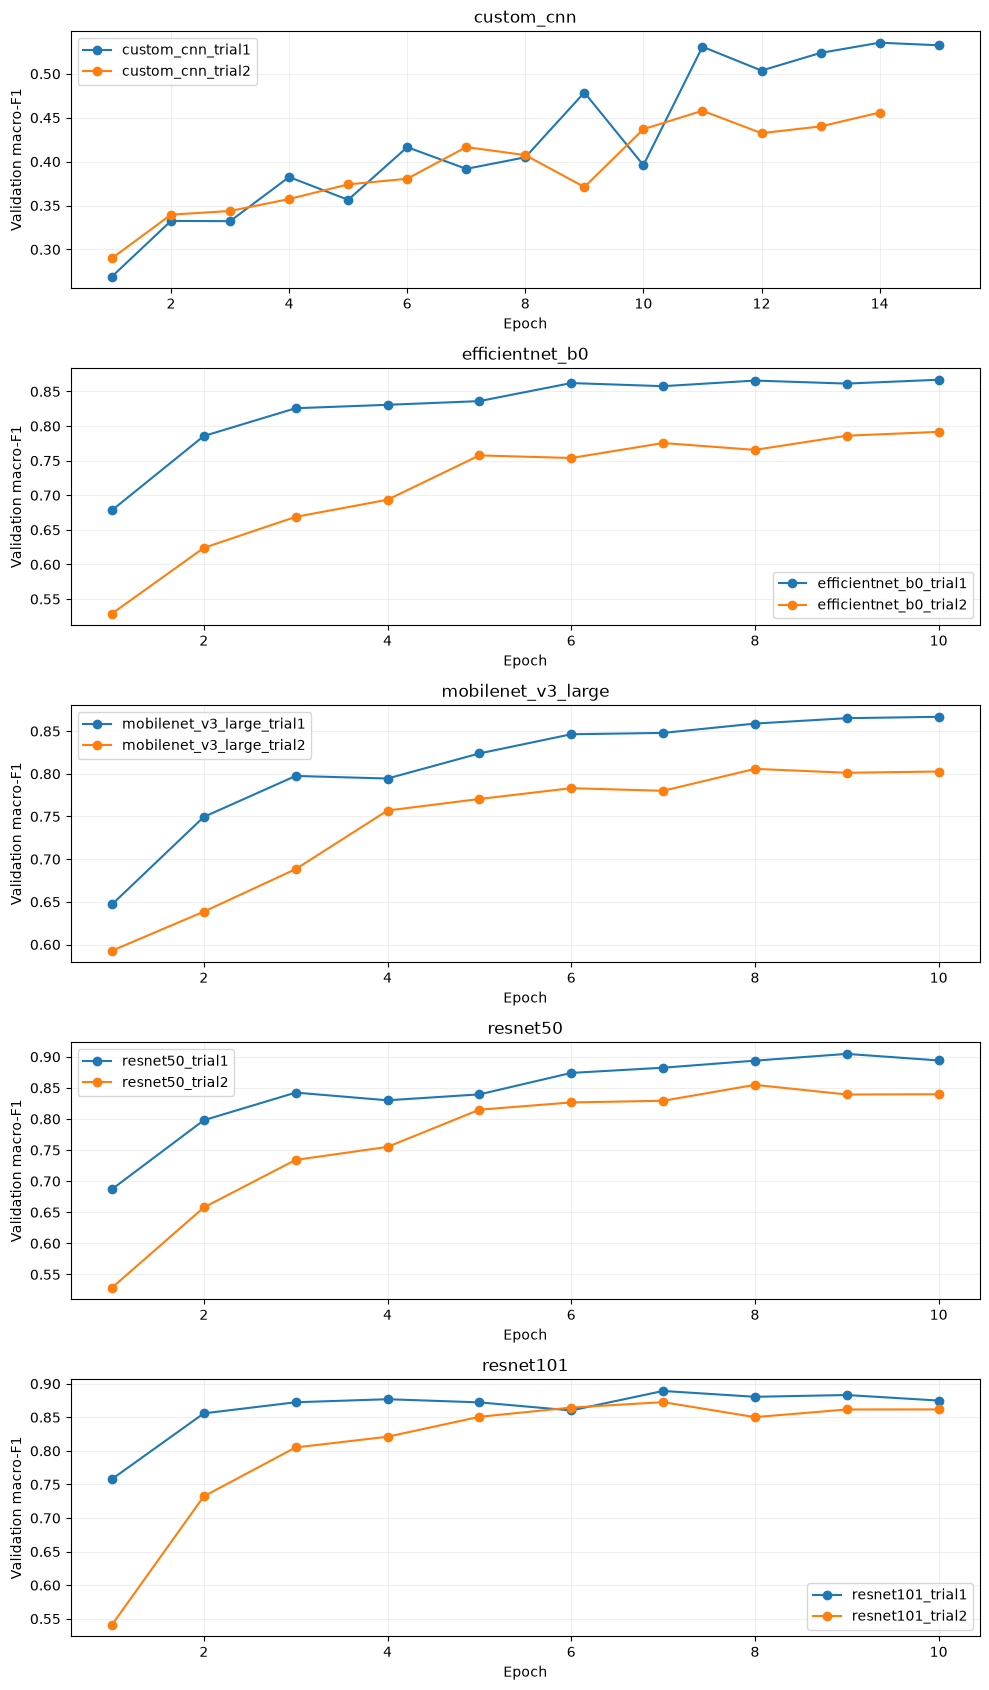

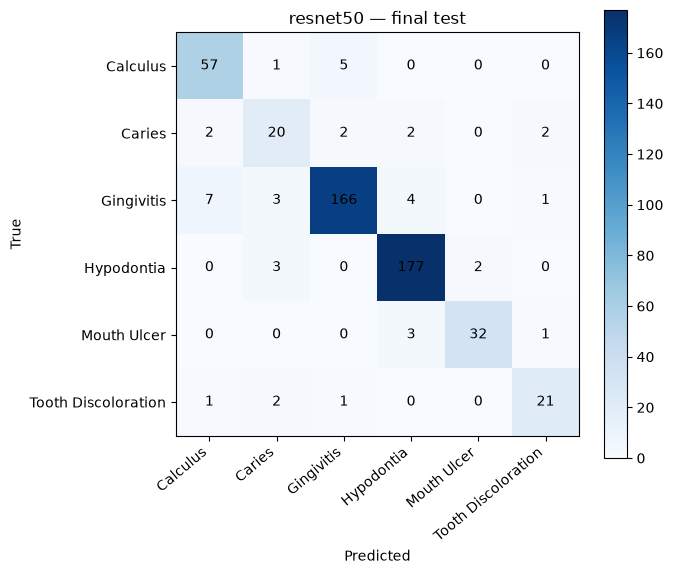

,precision,recall,f1-score,support
Calculus,0.850746,0.904762,0.876923,63.000000
Caries,0.689655,0.714286,0.701754,28.000000
Gingivitis,0.954023,0.917127,0.935211,181.000000
Hypodontia,0.951613,0.972527,0.961957,182.000000
Mouth Ulcer,0.941176,0.888889,0.914286,36.000000
Tooth Discoloration,0.840000,0.840000,0.840000,25.000000
accuracy,0.918447,0.918447,0.918447,0.918447
macro avg,0.871202,0.872932,0.871688,515.000000
weighted avg,0.919731,0.918447,0.918755,515.000000


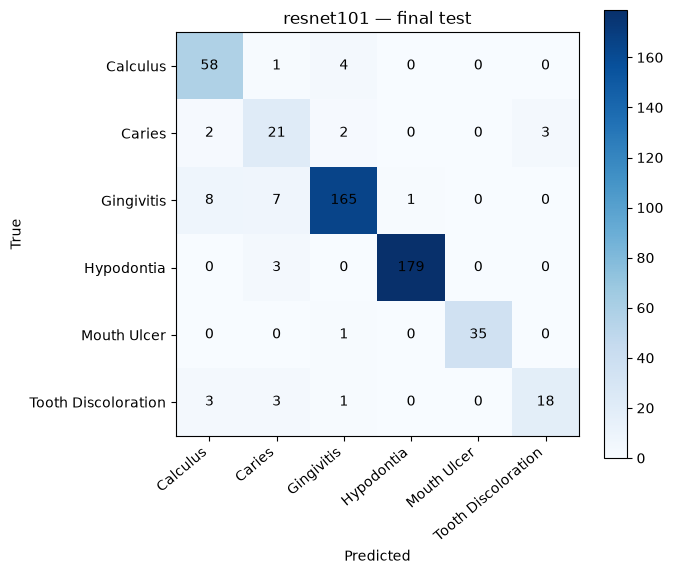

,precision,recall,f1-score,support
Calculus,0.816901,0.920635,0.865672,63.000000
Caries,0.600000,0.750000,0.666667,28.000000
Gingivitis,0.953757,0.911602,0.932203,181.000000
Hypodontia,0.994444,0.983516,0.988950,182.000000
Mouth Ulcer,1.000000,0.972222,0.985915,36.000000
Tooth Discoloration,0.857143,0.720000,0.782609,25.000000
accuracy,0.924272,0.924272,0.924272,0.924272
macro avg,0.870374,0.876329,0.870336,515.000000
weighted avg,0.930704,0.924272,0.926175,515.000000


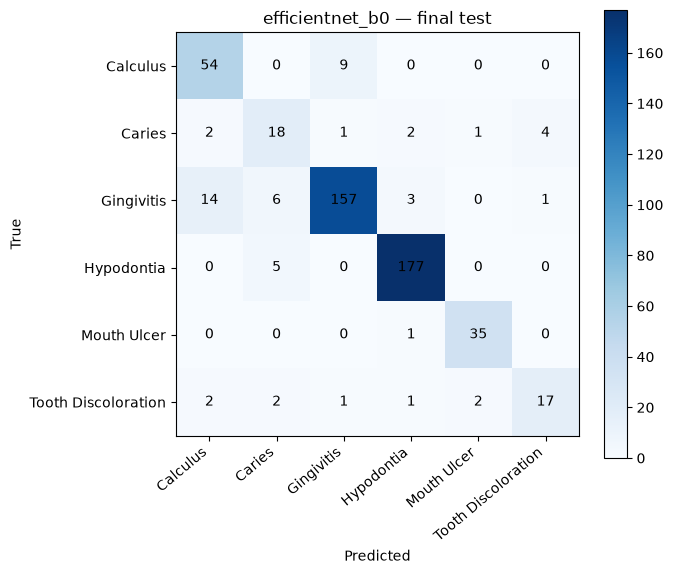

,precision,recall,f1-score,support
Calculus,0.750000,0.857143,0.800000,63.00000
Caries,0.580645,0.642857,0.610169,28.00000
Gingivitis,0.934524,0.867403,0.899713,181.00000
Hypodontia,0.961957,0.972527,0.967213,182.00000
Mouth Ulcer,0.921053,0.972222,0.945946,36.00000
Tooth Discoloration,0.772727,0.680000,0.723404,25.00000
accuracy,0.889320,0.889320,0.889320,0.88932
macro avg,0.820151,0.832026,0.824408,515.00000
weighted avg,0.893610,0.889320,0.890301,515.00000


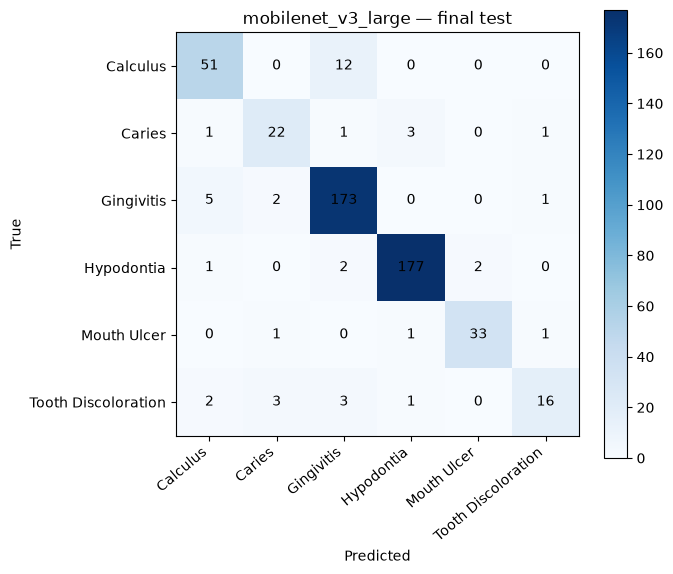

,precision,recall,f1-score,support
Calculus,0.850000,0.809524,0.829268,63.000000
Caries,0.785714,0.785714,0.785714,28.000000
Gingivitis,0.905759,0.955801,0.930108,181.000000
Hypodontia,0.972527,0.972527,0.972527,182.000000
Mouth Ulcer,0.942857,0.916667,0.929577,36.000000
Tooth Discoloration,0.842105,0.640000,0.727273,25.000000
accuracy,0.916505,0.916505,0.916505,0.916505
macro avg,0.883161,0.846706,0.862411,515.000000
weighted avg,0.915510,0.916505,0.915029,515.000000


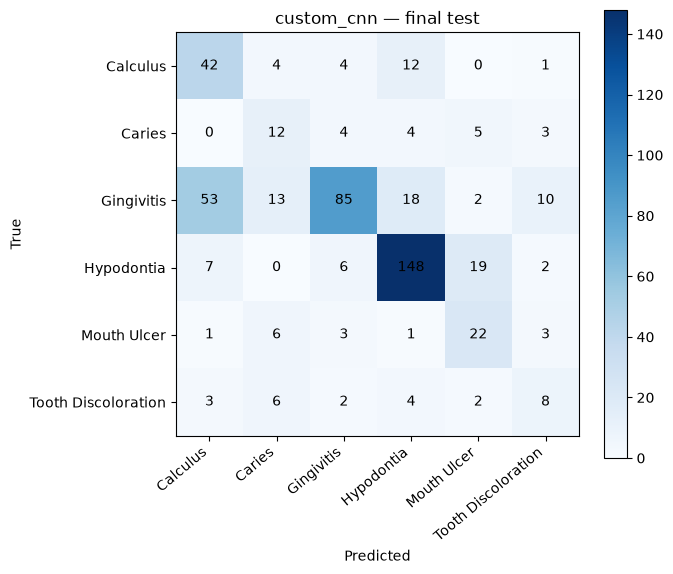

,precision,recall,f1-score,support
Calculus,0.396226,0.666667,0.497041,63.000000
Caries,0.292683,0.428571,0.347826,28.000000
Gingivitis,0.817308,0.469613,0.596491,181.000000
Hypodontia,0.791444,0.813187,0.802168,182.000000
Mouth Ulcer,0.440000,0.611111,0.511628,36.000000
Tooth Discoloration,0.296296,0.320000,0.307692,25.000000
accuracy,0.615534,0.615534,0.615534,0.615534
macro avg,0.505660,0.551525,0.510474,515.000000
weighted avg,0.676467,0.615534,0.623540,515.000000


Selected model bundle: /kaggle/working/oral_training/selected_model_bundle.zip


In [17]:
if status['status']=='COMPLETE':
    results=pd.read_csv(run_dir/'model_comparison.csv')
    display(results)
    selected=json.loads((run_dir/'selected_model.json').read_text())
    print('Selected using validation macro-F1:',selected['model'],selected['trial'])
    fig,axes=plt.subplots(5,1,figsize=(10,17))
    for ax,name in zip(axes,['custom_cnn','efficientnet_b0','mobilenet_v3_large','resnet50','resnet101']):
        for trial in [trial for trial in trials if trial['model']==name]:
            history=pd.read_csv(run_dir/trial['id']/'history.csv')
            ax.plot(history['epoch'],history['validation_macro_f1'],marker='o',label=trial['id'])
        ax.set_title(name);ax.set_ylabel('Validation macro-F1');ax.set_xlabel('Epoch');ax.legend();ax.grid(alpha=.2)
    plt.tight_layout();plt.savefig(run_dir/'validation_learning_curves.png',dpi=120);plt.show();plt.close(fig)
    for result in results.itertuples(index=False):
        matrix=pd.read_csv(run_dir/(result.trial+'_confusion_matrix.csv'),index_col=0)
        fig,ax=plt.subplots(figsize=(7,6));image=ax.imshow(matrix.to_numpy(),cmap='Blues')
        ax.set_xticks(range(6),CLASSES,rotation=40,ha='right');ax.set_yticks(range(6),CLASSES)
        ax.set_xlabel('Predicted');ax.set_ylabel('True');ax.set_title(result.model+' — final test')
        for row in range(6):
            for column in range(6):ax.text(column,row,str(matrix.iloc[row,column]),ha='center',va='center')
        fig.colorbar(image,ax=ax);plt.tight_layout();plt.savefig(run_dir/(result.trial+'_confusion_matrix.png'),dpi=120);plt.show();plt.close(fig)
        display(pd.read_csv(run_dir/(result.trial+'_per_class.csv'),index_col=0))
    bundle=run_dir/'selected_model_bundle.zip'
    with ZipFile(bundle,'w') as archive:
        archive.write(Path(selected['best_checkpoint']),arcname='best.pt')
        for name in ['selected_model.json','experiment_config.json','class_to_idx.json','data_policy.json','runtime.json','model_comparison.csv','train_kaggle.py']:
            archive.write(run_dir/name,arcname=name)
    print('Selected model bundle:',bundle)
else:
    print('Partial run: preserve oral_training (especially latest.pt files) and resume before interpreting a final comparison.')

---

Download the final trained model from that path on right side panel: `/kaggle/working/oral_training/selected_model_bundle.zip`